In [1]:
from pathlib import Path
import numpy as np

In [2]:
dataset_path = Path(r"C:\Users\User\OneDrive\Desktop\RoadVision AI\Datasets\RDD_SPLIT")

print("Dataset exists:", dataset_path.exists())
print("Dataset location:", dataset_path.resolve())

Dataset exists: True
Dataset location: C:\Users\User\OneDrive\Desktop\RoadVision AI\Datasets\RDD_SPLIT


In [3]:
xml_files = []

for file in dataset_path.rglob("*.xml"):
    xml_files.append(file)

print("XML files:", len(xml_files))

XML files: 0


In [4]:
txt_files = []

for file in dataset_path.rglob("*.txt"):
    txt_files.append(file)

print("TXT files:", len(txt_files))

TXT files: 38385


In [17]:
from pathlib import Path

txt_path = Path(r"C:\Users\User\OneDrive\Desktop\RoadVision AI\Datasets\Annotated_Additional_Dataset\TXT")

txt_files = list(txt_path.rglob("*.txt"))

print("Total TXT files:", len(txt_files))

if txt_files:
    print("Example file:", txt_files[0].name)
    print(txt_files[0].read_text())

Total TXT files: 713
Example file: Pothole-001.txt
0 0.428455 0.629067 0.593496 0.295011


In [27]:
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

# Step 1: Locate XML folder
xml_path = Path(r"C:\Users\User\OneDrive\Desktop\RoadVision AI\Datasets\Annotated_Additional_Dataset\XML")

print("Folder exists:", xml_path.exists())

# Step 2: Find all XML files
xml_files = list(xml_path.rglob("*.xml"))

print("Total XML files:", len(xml_files))

# Step 3: Create counter
class_counts = Counter()

# Step 4: Read each XML file
for xml_file in xml_files:
    tree = ET.parse(xml_file)
    root = tree.getroot()

    for obj in root.findall("object"):
        name = obj.findtext("name")
        class_counts[name] += 1

# Step 5: Print results
print("Damage classes:", class_counts)

Folder exists: True
Total XML files: 713
Damage classes: Counter({'pothole': 1156, 'o': 1})


In [28]:
for xml_file in xml_files:
    tree = ET.parse(xml_file)
    root = tree.getroot()

    for obj in root.findall("object"):
        name = obj.findtext("name")

        if name != "pothole":
            print("File:", xml_file.name)
            print("Unexpected class:", name)

File: Pothole-487.xml
Unexpected class: o


Matplotlib is building the font cache; this may take a moment.


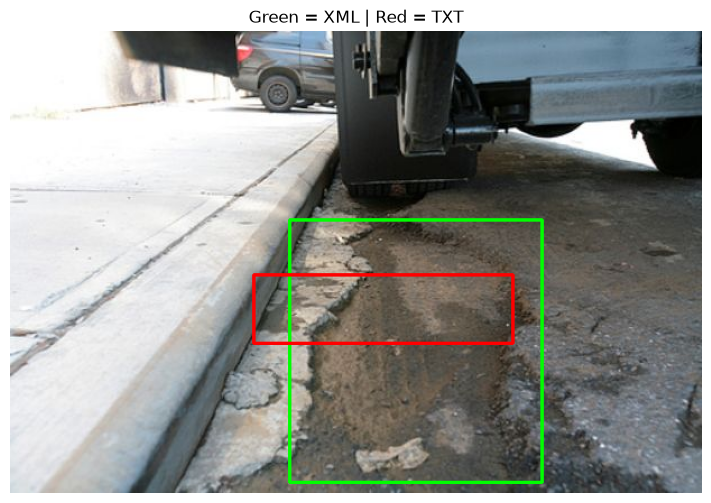

In [ ]:
import cv2
import matplotlib.pyplot as plt

image_path = xml_path.parent / "IMG" / "Pothole-487.jpg"

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(image_path)

height, width = image.shape[:2]

# XML bounding box (green)
cv2.rectangle(image, (249, 168), (474, 402), (0, 255, 0), 2)

# YOLO TXT bounding box (red)
x_center = 0.540000
y_center = 0.603155
box_width = 0.374545
box_height = 0.148058

xmin = int((x_center - box_width / 2) * width)
ymin = int((y_center - box_height / 2) * height)
xmax = int((x_center + box_width / 2) * width)
ymax = int((y_center + box_height / 2) * height)

cv2.rectangle(image, (xmin, ymin), (xmax, ymax), (0, 0, 255), 2)

# Display in notebook
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Green = XML | Red = TXT")
plt.axis("off")
plt.show()

In [31]:
from pathlib import Path

dataset_path = Path.cwd() / "Datasets" / "Annotated_Additional_Dataset"

xml_path = dataset_path / "XML"
txt_path = dataset_path / "TXT"
img_path = dataset_path / "IMG"

print("XML folder:", xml_path.exists())
print("TXT folder:", txt_path.exists())
print("IMG folder:", img_path.exists())

XML folder: True
TXT folder: True
IMG folder: True


In [32]:
xml_files = {
    f.stem.lower(): f
    for f in xml_path.rglob("*")
    if f.suffix.lower() == ".xml"
}

txt_files = {
    f.stem.lower(): f
    for f in txt_path.rglob("*")
    if f.suffix.lower() == ".txt"
}

img_files = {
    f.stem.lower(): f
    for f in img_path.rglob("*")
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

print("XML files:", len(xml_files))
print("TXT files:", len(txt_files))
print("Images:", len(img_files))

XML files: 713
TXT files: 713
Images: 713


In [33]:
xmin = 249
ymin = 168
xmax = 474
ymax = 402

import xml.etree.ElementTree as ET

def read_xml_boxes(file_path):
    tree = ET.parse(file_path)
    root = tree.getroot()

    width = int(root.findtext("size/width"))
    height = int(root.findtext("size/height"))

    boxes = []

    for obj in root.findall("object"):
        bndbox = obj.find("bndbox")

        xmin = float(bndbox.findtext("xmin"))
        ymin = float(bndbox.findtext("ymin"))
        xmax = float(bndbox.findtext("xmax"))
        ymax = float(bndbox.findtext("ymax"))

        # Normalize coordinates
        boxes.append((
            xmin / width,
            ymin / height,
            xmax / width,
            ymax / height
        ))

    return boxes

In [34]:
print(read_xml_boxes(xml_files["pothole-487"]))

[(0.4035656401944895, 0.4077669902912621, 0.7682333873581848, 0.9757281553398058)]


In [35]:
def read_txt_boxes(file_path):
    boxes = []

    for line in file_path.read_text().splitlines():
        if not line.strip():
            continue

        values = line.split()

        class_id = int(values[0])
        xc, yc, w, h = map(float, values[1:])

        xmin = xc - w / 2
        ymin = yc - h / 2
        xmax = xc + w / 2
        ymax = yc + h / 2

        boxes.append((xmin, ymin, xmax, ymax))

    return boxes

In [36]:
print(read_txt_boxes(txt_files["pothole-487"]))

[(0.3527275, 0.529126, 0.7272725, 0.677184)]


In [37]:
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [38]:
xml_box = read_xml_boxes(xml_files["pothole-487"])[0]
txt_box = read_txt_boxes(txt_files["pothole-487"])[0]

print("IoU:", round(calculate_iou(xml_box, txt_box), 3))

IoU: 0.223


In [39]:
def match_boxes(xml_boxes, txt_boxes):
    candidates = []

    for i, xml_box in enumerate(xml_boxes):
        for j, txt_box in enumerate(txt_boxes):
            score = calculate_iou(xml_box, txt_box)
            candidates.append((score, i, j))

    candidates.sort(reverse=True)

    used_xml = set()
    used_txt = set()
    matched_scores = []

    for score, i, j in candidates:
        if i not in used_xml and j not in used_txt:
            matched_scores.append(score)
            used_xml.add(i)
            used_txt.add(j)

    return matched_scores

In [40]:
results = []

common_files = sorted(set(xml_files) & set(txt_files))

for name in common_files:
    xml_boxes = read_xml_boxes(xml_files[name])
    txt_boxes = read_txt_boxes(txt_files[name])

    scores = match_boxes(xml_boxes, txt_boxes)

    avg_iou = sum(scores) / len(scores) if scores else 0

    results.append({
        "filename": name,
        "xml_boxes": len(xml_boxes),
        "txt_boxes": len(txt_boxes),
        "matched_boxes": len(scores),
        "avg_iou": avg_iou
    })

print("Files compared:", len(results))

low_iou = [r for r in results if r["avg_iou"] < 0.5]

print("Files with average IoU below 0.5:", len(low_iou))
print("XML files without matching TXT:", len(set(xml_files) - set(txt_files)))
print("TXT files without matching XML:", len(set(txt_files) - set(xml_files)))

Files compared: 713
Files with average IoU below 0.5: 144
XML files without matching TXT: 0
TXT files without matching XML: 0


In [41]:
import pandas as pd

df = pd.DataFrame(results)

df = df.sort_values("avg_iou")

display(df.head(10))

,filename,xml_boxes,txt_boxes,matched_boxes,avg_iou
448,pothole-449,1,1,1,0.000000
482,pothole-483,1,1,1,0.000000
451,pothole-452,1,1,1,0.000000
539,pothole-540,1,1,1,0.000000
505,pothole-506,1,1,1,0.000000
553,pothole-554,1,1,1,0.000000
693,pothole-694,2,2,2,0.001794
610,pothole-611,1,1,1,0.026153
590,pothole-591,2,2,2,0.026696
632,pothole-633,1,1,1,0.035020


In [42]:
import cv2
import matplotlib.pyplot as plt

def compare_image(filename):
    name = Path(filename).stem.lower()

    image = cv2.imread(str(img_files[name]))

    if image is None:
        raise ValueError("Image could not be opened")

    height, width = image.shape[:2]

    xml_boxes = read_xml_boxes(xml_files[name])
    txt_boxes = read_txt_boxes(txt_files[name])

    for x1, y1, x2, y2 in xml_boxes:
        cv2.rectangle(
            image,
            (int(x1 * width), int(y1 * height)),
            (int(x2 * width), int(y2 * height)),
            (0, 255, 0),
            2
        )

    for x1, y1, x2, y2 in txt_boxes:
        cv2.rectangle(
            image,
            (int(x1 * width), int(y1 * height)),
            (int(x2 * width), int(y2 * height)),
            (0, 0, 255),
            2
        )

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"{filename} | Green = XML, Red = TXT")
    plt.axis("off")
    plt.show()

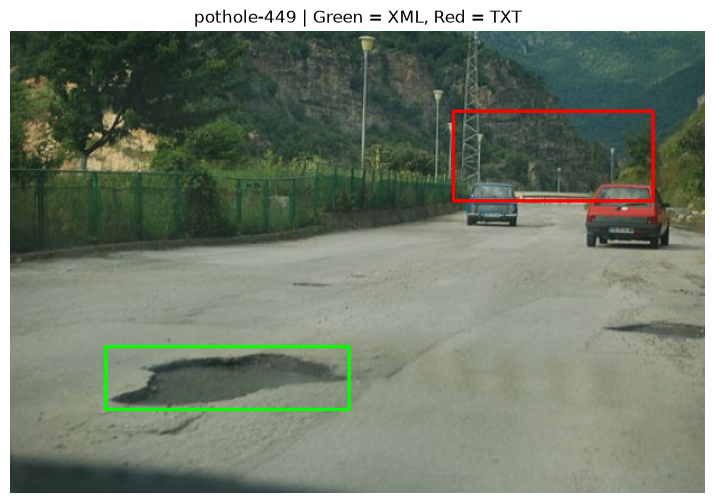

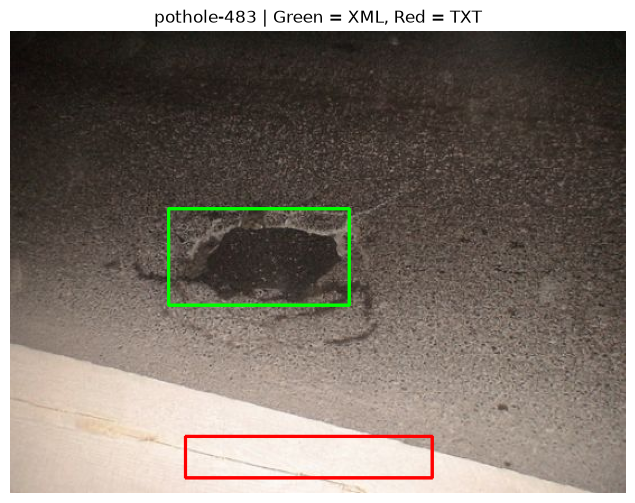

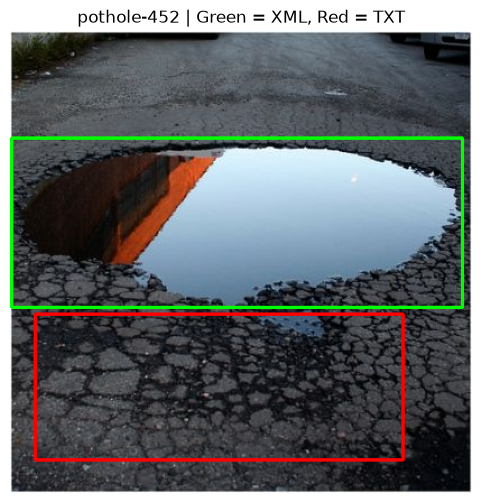

In [44]:
for name in df.head(3)["filename"]:
    compare_image(name)

In [45]:
import csv
import xml.etree.ElementTree as ET
from pathlib import Path

review_path = Path.cwd() / "additional_review.csv"

rows = []

for name, xml_file in sorted(xml_files.items()):
    root = ET.parse(xml_file).getroot()

    for index, obj in enumerate(root.findall("object")):
        rows.append({
            "filename": name,
            "object_index": index,
            "original_class": obj.findtext("name"),
            "final_class": "",
            "notes": ""
        })

# Avoid overwriting work if the CSV already exists
if not review_path.exists():
    with open(review_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

print("Objects to review:", len(rows))
print("Review CSV:", review_path)

Objects to review: 1157
Review CSV: c:\Users\User\OneDrive\Desktop\RoadVision AI\additional_review.csv


In [46]:
from pathlib import Path
from collections import Counter

rdd_path = Path.cwd() / "Datasets" / "RDD_SPLIT"

for split in ["train", "val", "test"]:

    image_folder = rdd_path / split / "images"
    label_folder = rdd_path / split / "labels"

    images = [
        f for f in image_folder.rglob("*")
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    labels = list(label_folder.rglob("*.txt"))

    class_counts = Counter()

    for label in labels:
        for line in label.read_text(encoding="utf-8").splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("TXT labels:", len(labels))
    print("Class counts:", class_counts)


TRAIN
Images: 26869
TXT labels: 26869
Class counts: Counter({0: 18201, 1: 8386, 3: 7554, 2: 7527, 4: 4628})

VAL
Images: 5758
TXT labels: 5758
Class counts: Counter({0: 3890, 1: 1769, 3: 1564, 2: 1553, 4: 965})

TEST
Images: 5758
TXT labels: 5758
Class counts: Counter({0: 3925, 1: 1675, 3: 1587, 2: 1537, 4: 951})


In [47]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

rdd_path = Path.cwd() / "Datasets" / "RDD_SPLIT"

image_folder = rdd_path / "train" / "images"
label_folder = rdd_path / "train" / "labels"

image_files = {
    f.stem.lower(): f
    for f in image_folder.rglob("*")
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

def show_class_samples(class_id, count=3):
    matching = []

    for label_file in label_folder.rglob("*.txt"):
        lines = label_file.read_text().splitlines()

        if any(
            line.strip() and line.split()[0] == str(class_id)
            for line in lines
        ):
            name = label_file.stem.lower()

            if name in image_files:
                matching.append((image_files[name], label_file))

    random.Random(42).shuffle(matching)

    print(f"Images containing class {class_id}: {len(matching)}")

    for image_path, label_path in matching[:count]:
        image = cv2.imread(str(image_path))

        if image is None:
            continue

        height, width = image.shape[:2]

        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue

            values = line.split()
            cid = int(values[0])

            if cid != class_id:
                continue

            xc, yc, w, h = map(float, values[1:5])

            x1 = int((xc - w / 2) * width)
            y1 = int((yc - h / 2) * height)
            x2 = int((xc + w / 2) * width)
            y2 = int((yc + h / 2) * height)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

        plt.figure(figsize=(9, 5))
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title(f"Class {class_id}: {image_path.name}")
        plt.axis("off")
        plt.show()

Images containing class 3: 5247


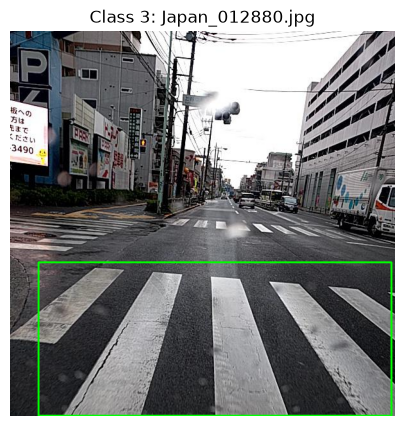

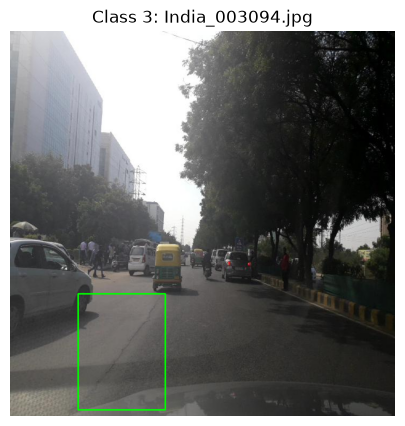

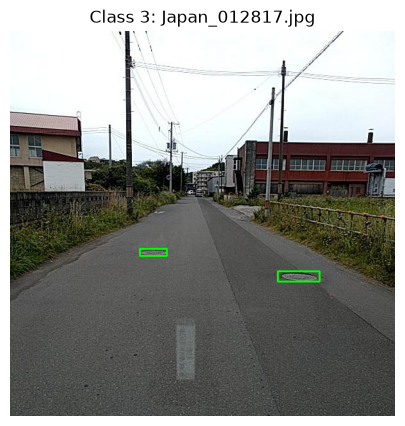

Images containing class 4: 2599


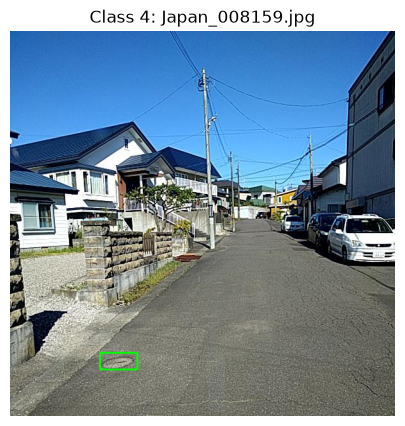

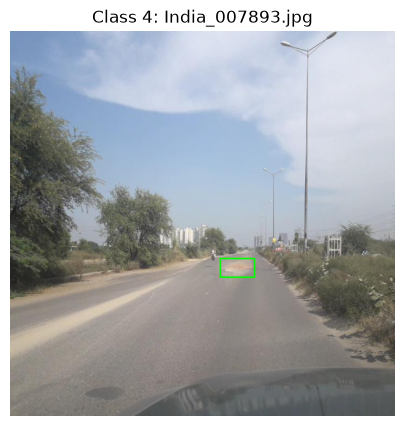

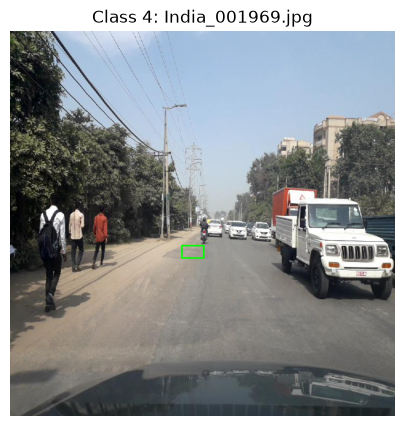

In [48]:
show_class_samples(3)
show_class_samples(4)

In [49]:
from pathlib import Path
from collections import Counter

rdd_path = Path.cwd() / "Datasets" / "RDD_SPLIT"
output_path = Path.cwd() / "Datasets" / "RDD_RELABELED"

# Original class -> final RoadScan AI class
class_mapping = {
    0: 0,  # Longitudinal Crack
    1: 1,  # Transverse Crack
    2: 2,  # Alligator Crack
    4: 3   # Pothole
}

for split in ["train", "val", "test"]:

    input_folder = rdd_path / split / "labels"
    output_folder = output_path / split / "labels"

    output_folder.mkdir(parents=True, exist_ok=True)

    new_counts = Counter()
    excluded = 0

    for label_file in input_folder.rglob("*.txt"):

        new_lines = []

        for line in label_file.read_text().splitlines():

            if not line.strip():
                continue

            parts = line.split()
            old_class = int(parts[0])

            # Exclude the extra category
            if old_class == 3:
                excluded += 1
                continue

            if old_class not in class_mapping:
                raise ValueError(f"Unexpected class: {old_class}")

            new_class = class_mapping[old_class]

            parts[0] = str(new_class)
            new_lines.append(" ".join(parts))

            new_counts[new_class] += 1

        destination = output_folder / label_file.relative_to(input_folder)
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_text("\n".join(new_lines))

    print(f"\n{split.upper()}")
    print("Class counts:", new_counts)
    print("Excluded annotations:", excluded)


TRAIN
Class counts: Counter({0: 18201, 1: 8386, 2: 7527, 3: 4628})
Excluded annotations: 7554

VAL
Class counts: Counter({0: 3890, 1: 1769, 2: 1553, 3: 965})
Excluded annotations: 1564

TEST
Class counts: Counter({0: 3925, 1: 1675, 2: 1537, 3: 951})
Excluded annotations: 1587


In [50]:
from pathlib import Path

rdd_path = Path.cwd() / "Datasets" / "RDD_SPLIT"
output_path = Path.cwd() / "Datasets" / "RDD_RELABELED"

for split in ["train", "val", "test"]:
    image_folder = rdd_path / split / "images"
    label_folder = output_path / split / "labels"

    images = {
        p.stem.lower()
        for p in image_folder.rglob("*")
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    }

    labels = list(label_folder.rglob("*.txt"))
    label_names = {p.stem.lower() for p in labels}

    invalid = []
    empty = 0

    for file in labels:
        lines = [s for s in file.read_text().splitlines() if s.strip()]

        if not lines:
            empty += 1

        for line in lines:
            try:
                values = line.split()
                if len(values) != 5:
                    raise ValueError("Wrong number of values")

                class_id = int(values[0])
                x, y, w, h = map(float, values[1:])

                if class_id not in [0, 1, 2, 3]:
                    raise ValueError("Invalid class")

                if not (
                    0 < w <= 1 and 0 < h <= 1
                    and 0 <= x - w/2
                    and x + w/2 <= 1
                    and 0 <= y - h/2
                    and y + h/2 <= 1
                ):
                    raise ValueError("Invalid bounding box")

            except ValueError:
                invalid.append(file.name)

    print(f"\n{split.upper()}")
    print("Missing labels:", len(images - label_names))
    print("Labels without images:", len(label_names - images))
    print("Empty labels:", empty)
    print("Invalid annotations:", len(invalid))


TRAIN
Missing labels: 0
Labels without images: 0
Empty labels: 10138
Invalid annotations: 1812

VAL
Missing labels: 0
Labels without images: 0
Empty labels: 2265
Invalid annotations: 378

TEST
Missing labels: 0
Labels without images: 0
Empty labels: 2215
Invalid annotations: 383


In [51]:
from pathlib import Path
from collections import Counter
import math

output_path = Path.cwd() / "Datasets" / "RDD_RELABELED"

for split in ["train", "val", "test"]:

    label_folder = output_path / split / "labels"

    problems = Counter()
    examples = []

    for file in label_folder.rglob("*.txt"):

        for line_number, line in enumerate(
            file.read_text().splitlines(), start=1
        ):

            if not line.strip():
                continue

            values = line.split()
            reason = None

            if len(values) != 5:
                reason = "Wrong number of values"

            else:
                try:
                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])

                    if not all(math.isfinite(v) for v in (x, y, w, h)):
                        reason = "Non-finite coordinate"

                    elif class_id not in [0, 1, 2, 3]:
                        reason = "Invalid class ID"

                    elif w <= 0 or h <= 0:
                        reason = "Invalid width or height"

                    elif not (0 <= x <= 1 and 0 <= y <= 1):
                        reason = "Center outside image"

                    else:
                        overflow = max(
                            0,
                            -(x - w / 2),
                            x + w / 2 - 1,
                            -(y - h / 2),
                            y + h / 2 - 1
                        )

                        if overflow > 0:
                            if overflow <= 0.001:
                                reason = "Tiny boundary overflow"
                            else:
                                reason = "Box outside image"

                except ValueError:
                    reason = "Non-numeric annotation"

            if reason:
                problems[reason] += 1

                if len(examples) < 5:
                    examples.append(
                        (file.name, line_number, reason, line)
                    )

    print(f"\n{split.upper()}")
    print("Problems:", problems)

    for example in examples:
        print("Example:", example)


TRAIN
Problems: Counter({'Tiny boundary overflow': 1811, 'Invalid width or height': 1})
Example: ('China_Drone_000024.txt', 1, 'Tiny boundary overflow', '0 0.057617 0.500977 0.060547 0.998047')
Example: ('China_Drone_000051.txt', 1, 'Tiny boundary overflow', '1 0.719727 0.637695 0.560547 0.166016')
Example: ('China_Drone_000055.txt', 1, 'Tiny boundary overflow', '0 0.854492 0.500977 0.091797 0.998047')
Example: ('China_Drone_000060.txt', 1, 'Tiny boundary overflow', '1 0.500977 0.198242 0.998047 0.158203')
Example: ('China_Drone_000078.txt', 1, 'Tiny boundary overflow', '1 0.500977 0.454102 0.998047 0.146484')

VAL
Problems: Counter({'Tiny boundary overflow': 378})
Example: ('China_Drone_000130.txt', 2, 'Tiny boundary overflow', '0 0.631836 0.500977 0.169922 0.998047')
Example: ('China_Drone_000139.txt', 1, 'Tiny boundary overflow', '1 0.500977 0.620117 0.998047 0.115234')
Example: ('China_Drone_000210.txt', 1, 'Tiny boundary overflow', '0 0.315430 0.500977 0.087891 0.998047')
Example

In [52]:
original = Path.cwd() / "Datasets" / "RDD_SPLIT"
corrected = Path.cwd() / "Datasets" / "RDD_RELABELED"

for split in ["train", "val", "test"]:

    original_folder = original / split / "labels"
    corrected_folder = corrected / split / "labels"

    originally_empty = 0
    became_empty = 0

    for original_file in original_folder.rglob("*.txt"):

        relative_path = original_file.relative_to(original_folder)
        corrected_file = corrected_folder / relative_path

        old_text = original_file.read_text().strip()
        new_text = corrected_file.read_text().strip()

        if not old_text:
            originally_empty += 1

        elif not new_text:
            became_empty += 1

    print(f"\n{split.upper()}")
    print("Originally empty:", originally_empty)
    print("Became empty after relabeling:", became_empty)


TRAIN
Originally empty: 8097
Became empty after relabeling: 2041

VAL
Originally empty: 1837
Became empty after relabeling: 428

TEST
Originally empty: 1790
Became empty after relabeling: 425


In [53]:
from pathlib import Path

corrected = Path.cwd() / "Datasets" / "RDD_RELABELED"

for split in ["train", "val", "test"]:

    folder = corrected / split / "labels"

    overflows = []
    invalid_sizes = []

    for file in folder.rglob("*.txt"):
        for line_number, line in enumerate(
            file.read_text().splitlines(), start=1
        ):
            if not line.strip():
                continue

            cls, x, y, w, h = map(float, line.split())

            if w <= 0 or h <= 0:
                invalid_sizes.append((file.name, line_number, line))
                continue

            overflow = max(
                0,
                w/2 - x,
                x + w/2 - 1,
                h/2 - y,
                y + h/2 - 1
            )

            if overflow > 0:
                overflows.append(overflow)

    print(f"\n{split.upper()}")

    if overflows:
        print("Maximum overflow:", max(overflows))
        print("Overflow above 0.000001:",
              sum(v > 0.000001 for v in overflows))

    print("Invalid sizes:", invalid_sizes)


TRAIN
Maximum overflow: 5.00000000069889e-07
Overflow above 0.000001: 0
Invalid sizes: [('Japan_001265.txt', 4, '2 0.330000 0.790833 0.000000 0.001667')]

VAL
Maximum overflow: 5.00000000069889e-07
Overflow above 0.000001: 0
Invalid sizes: []

TEST
Maximum overflow: 5.00000000069889e-07
Overflow above 0.000001: 0
Invalid sizes: []


In [54]:
from pathlib import Path

label_path = (
    Path.cwd()
    / "Datasets"
    / "RDD_RELABELED"
    / "train"
    / "labels"
    / "Japan_001265.txt"
)

lines = label_path.read_text().splitlines()

for index, line in enumerate(lines, start=1):
    print(f"Line {index}: {line}")

Line 1: 0 0.448333 0.749167 0.100000 0.261667
Line 2: 2 0.650833 0.947500 0.395000 0.105000
Line 3: 2 0.094167 0.743333 0.158333 0.110000
Line 4: 2 0.330000 0.790833 0.000000 0.001667


In [55]:
from pathlib import Path
import shutil

source = Path.cwd() / "Datasets" / "RDD_RELABELED"
destination = Path.cwd() / "Datasets" / "RDD_CLEANED"

for split in ["train", "val", "test"]:
    shutil.copytree(
        source / split / "labels",
        destination / split / "labels"
    )

print("Cleaned dataset copy created.")

Cleaned dataset copy created.


In [56]:
file = destination / "train" / "labels" / "Japan_001265.txt"

lines = file.read_text().splitlines()

invalid_line = "2 0.330000 0.790833 0.000000 0.001667"

assert lines[3].strip() == invalid_line

del lines[3]

file.write_text("\n".join(lines) + "\n")

print("Removed invalid annotation.")

Removed invalid annotation.


In [57]:
tolerance = 1e-6
invalid_count = 0

for split in ["train", "val", "test"]:

    label_folder = destination / split / "labels"

    for file in label_folder.rglob("*.txt"):

        for line in file.read_text().splitlines():

            if not line.strip():
                continue

            cls, x, y, w, h = map(float, line.split())

            if (
                w <= 0 or h <= 0
                or x - w/2 < -tolerance
                or y - h/2 < -tolerance
                or x + w/2 > 1 + tolerance
                or y + h/2 > 1 + tolerance
            ):
                invalid_count += 1

print("Invalid annotations:", invalid_count)

Invalid annotations: 0


In [59]:
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd

dataset_path = Path.cwd() / "Datasets" / "Annotated_Additional_Dataset"

xml_path = dataset_path / "XML"

records = []

for xml_file in sorted(xml_path.rglob("*.xml")):

    tree = ET.parse(xml_file)
    root = tree.getroot()

    for index, obj in enumerate(root.findall("object")):

        records.append({
            "filename": xml_file.stem,
            "object_index": index,
            "original_class": obj.findtext("name"),
            "final_class": "",
        })

df_review = pd.DataFrame(records)

csv_path = Path.cwd() / "additional_review.csv"

if not csv_path.exists():
    df_review.to_csv(csv_path, index=False)
    print("CSV created successfully!")
else:
    print("Review CSV already exists; not overwriting it.")

print("Total annotated objects:", len(df_review))
display(df_review.head(10))

Review CSV already exists; not overwriting it.
Total annotated objects: 1157


,filename,object_index,original_class,final_class
0,Pothole-001,0,pothole,
1,Pothole-002,0,pothole,
2,Pothole-003,0,pothole,
3,Pothole-004,0,pothole,
4,Pothole-004,1,pothole,
5,Pothole-005,0,pothole,
6,Pothole-006,0,pothole,
7,Pothole-007,0,pothole,
8,Pothole-007,1,pothole,
9,Pothole-008,0,pothole,


In [60]:
import pandas as pd

review = pd.read_csv(csv_path)

print("Saved CSV rows:", len(review))
print("Unclassified objects:", review["final_class"].isna().sum())

display(review.head(10))

Saved CSV rows: 1157
Unclassified objects: 1157


,filename,object_index,original_class,final_class,notes
0,pothole-001,0,pothole,NaN,NaN
1,pothole-002,0,pothole,NaN,NaN
2,pothole-003,0,pothole,NaN,NaN
3,pothole-004,0,pothole,NaN,NaN
4,pothole-004,1,pothole,NaN,NaN
5,pothole-005,0,pothole,NaN,NaN
6,pothole-006,0,pothole,NaN,NaN
7,pothole-007,0,pothole,NaN,NaN
8,pothole-007,1,pothole,NaN,NaN
9,pothole-008,0,pothole,NaN,NaN


In [61]:
review.loc[
    (review["filename"].str.lower() == "pothole-452") &
    (review["object_index"] == 0),
    "final_class"
] = 4

display(review[review["filename"].str.lower() == "pothole-452"])

,filename,object_index,original_class,final_class,notes
742,pothole-452,0,pothole,4.0,NaN


In [62]:
review.to_csv(csv_path, index=False)
print("Classification saved!")

Classification saved!


In [63]:
%pip install ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ------------------ --------------------- 1.0/2.2 MB 25.4 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 4.2 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 4.2 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 4.2 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 4.2 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 4.2 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 4.2 MB/s eta 0:00:01
   ---------------------------- ----------- 1.6/2.2 MB 873.8 kB/s eta 0:00:01
   ---------------------------- ----------- 1.6/2.2 MB 873.8 kB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 947.3 kB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 947.3 kB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 947.3 kB/s eta 0:00:01
   -----

In [ ]:
from pathlib import Path
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Locate dataset and load existing CSV
project_path = Path.cwd()
csv_path = project_path / "additional_review.csv"

datasets_path = project_path / "Datasets"

dataset_path = next(
    (
        p for p in datasets_path.iterdir()
        if p.is_dir()
        and "additional" in p.name.lower()
        and (p / "XML").is_dir()
        and (p / "IMG").is_dir()
    ),
    None
)

assert dataset_path is not None, "Additional dataset not found"
assert csv_path.exists(), "Review CSV not found"

xml_path = dataset_path / "XML"
img_path = dataset_path / "IMG"

review = pd.read_csv(csv_path)

# Match XML and image files by filename
xml_files = {
    f.stem.lower(): f
    for f in xml_path.rglob("*.xml")
}

img_files = {
    f.stem.lower(): f
    for f in img_path.rglob("*")
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

# Resume from the first unclassified object
unclassified = review[review["final_class"].isna()].index

position = [int(unclassified[0]) if len(unclassified) else len(review)]

# 2. Create interface buttons
ordinary_btn = widgets.Button(
    description="Ordinary Pothole (3)",
    button_style="info"
)

water_btn = widgets.Button(
    description="Water-Filled (4)",
    button_style="success"
)

skip_btn = widgets.Button(description="Skip / Next")
back_btn = widgets.Button(description="Previous")

progress = widgets.HTML()
output = widgets.Output()

# 3. Display the current annotated object
def show_image():

    with output:
        clear_output(wait=True)

        if position[0] >= len(review):
            print("Reached the end of the review.")
            print("Re-run this cell to revisit skipped objects.")
            return

        row = review.iloc[position[0]]

        name = str(row["filename"]).lower()
        object_index = int(row["object_index"])

        image_path = img_files.get(name)
        xml_file = xml_files.get(name)

        if image_path is None or xml_file is None:
            print("Missing image or XML:", name)
            return

        image = cv2.imread(str(image_path))

        if image is None:
            print("Cannot read image:", image_path)
            return

        root = ET.parse(xml_file).getroot()
        objects = root.findall("object")

        if object_index >= len(objects):
            print("Invalid object index:", name)
            return

        obj = objects[object_index]
        bbox = obj.find("bndbox")

        xmin = int(float(bbox.findtext("xmin")))
        ymin = int(float(bbox.findtext("ymin")))
        xmax = int(float(bbox.findtext("xmax")))
        ymax = int(float(bbox.findtext("ymax")))

        cv2.rectangle(
            image,
            (xmin, ymin),
            (xmax, ymax),
            (0, 255, 0),
            3
        )

        plt.figure(figsize=(9, 6))
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title(f"{name} | Object {object_index}")
        plt.axis("off")
        plt.show()
        plt.close()

        completed = review["final_class"].notna().sum()

        progress.value = (
            f"<b>Classified: {completed} / {len(review)}</b>"
            f" | Current row: {position[0] + 1}"
        )

# 4. Save classification
def save_class(class_id):
    review.at[position[0], "final_class"] = class_id
    review.to_csv(csv_path, index=False)

    position[0] += 1
    show_image()

# 5. Button events
ordinary_btn.on_click(lambda b: save_class(3))
water_btn.on_click(lambda b: save_class(4))

def skip_image(b):
    position[0] += 1
    show_image()

def previous_image(b):
    position[0] = max(0, position[0] - 1)
    show_image()

skip_btn.on_click(skip_image)
back_btn.on_click(previous_image)

# 6. Display interface
display(progress)
display(output)

display(widgets.HBox([
    ordinary_btn,
    water_btn,
    skip_btn,
    back_btn
]))

show_image()

HTML(value='')

Output()

In [ ]:
print("Jupyter is working!")

In [1]:
import ipywidgets as widgets
from IPython.display import display

ordinary_btn = widgets.Button(
    description="Ordinary Pothole (3)",
    button_style="info"
)

water_btn = widgets.Button(
    description="Water-Filled (4)",
    button_style="success"
)

display(widgets.HBox([ordinary_btn, water_btn]))

In [2]:
import pandas as pd
from pathlib import Path

csv_path = Path.cwd() / "additional_review.csv"

review = pd.read_csv(csv_path)

print("Total objects:", len(review))
print("Classified:", review["final_class"].notna().sum())
print("Remaining:", review["final_class"].isna().sum())

Total objects: 1157
Classified: 1
Remaining: 1156


In [3]:
import ipywidgets as widgets
from IPython.display import display

button = widgets.Button(description="Click Me")
output = widgets.Output()

def on_click(b):
    with output:
        print("Button works!")

button.on_click(on_click)

display(button, output)

Button(description='Click Me', style=ButtonStyle())

Output()

In [4]:
from pathlib import Path
import pandas as pd
import cv2
import xml.etree.ElementTree as ET
import ipywidgets as widgets
from IPython.display import display

# Project folder
project_path = Path.cwd()

# Existing CSV
csv_path = project_path / "additional_review.csv"
review = pd.read_csv(csv_path)

# Find the additional dataset
datasets_path = project_path / "Datasets"

folders = [
    p for p in datasets_path.iterdir()
    if p.is_dir()
    and (p / "XML").is_dir()
    and (p / "IMG").is_dir()
]

assert len(folders) == 1, f"Expected one additional dataset, found: {folders}"

dataset_path = folders[0]

xml_path = dataset_path / "XML"
img_path = dataset_path / "IMG"

# Create filename lookup dictionaries
xml_files = {
    p.stem.lower(): p
    for p in xml_path.rglob("*.xml")
}

img_files = {
    p.stem.lower(): p
    for p in img_path.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

print("Total objects:", len(review))
print("Classified:", review["final_class"].notna().sum())
print("Remaining:", review["final_class"].isna().sum())
print("Images found:", len(img_files))

Total objects: 1157
Classified: 1
Remaining: 1156
Images found: 713


In [5]:
# Resume from the first unclassified object
remaining = review.index[review["final_class"].isna()].tolist()
position = [remaining[0] if remaining else 0]

# Interface components
preview = widgets.Image(format="jpeg")

progress = widgets.HTML()
message = widgets.HTML()

ordinary_btn = widgets.Button(
    description="Ordinary (3)",
    button_style="info"
)

water_btn = widgets.Button(
    description="Water-Filled (4)",
    button_style="success"
)

skip_btn = widgets.Button(description="Skip")
previous_btn = widgets.Button(description="Previous")


def show_current():

    completed = review["final_class"].notna().sum()

    if completed == len(review):
        progress.value = "<b>All objects classified!</b>"
        preview.value = b""
        return

    i = position[0]
    row = review.iloc[i]

    name = str(row["filename"]).lower()
    obj_index = int(row["object_index"])

    if name not in img_files or name not in xml_files:
        message.value = f"Missing file: {name}"
        return

    # Load only the current image
    image = cv2.imread(str(img_files[name]))

    if image is None:
        message.value = f"Cannot read image: {name}"
        return

    # Read XML bounding box
    root = ET.parse(xml_files[name]).getroot()
    objects = root.findall("object")

    if obj_index >= len(objects):
        message.value = f"Invalid object index: {name}"
        return

    box = objects[obj_index].find("bndbox")

    x1 = int(float(box.findtext("xmin")))
    y1 = int(float(box.findtext("ymin")))
    x2 = int(float(box.findtext("xmax")))
    y2 = int(float(box.findtext("ymax")))

    # Resize for faster display
    h, w = image.shape[:2]
    scale = min(1.0, 850 / max(w, h))

    if scale < 1:
        image = cv2.resize(image, None, fx=scale, fy=scale)

    # Draw current object's box
    cv2.rectangle(
        image,
        (round(x1 * scale), round(y1 * scale)),
        (round(x2 * scale), round(y2 * scale)),
        (0, 255, 0),
        3
    )

    # Encode image in memory
    success, encoded = cv2.imencode(
        ".jpg", image,
        [cv2.IMWRITE_JPEG_QUALITY, 80]
    )

    if not success:
        message.value = "Image encoding failed"
        return

    preview.value = encoded.tobytes()

    current_class = row["final_class"]
    label = "Unclassified" if pd.isna(current_class) else str(int(current_class))

    progress.value = (
        f"<b>Completed: {completed}/{len(review)}</b>"
        f" | File: {name}"
        f" | Object: {obj_index}"
        f" | Current class: {label}"
    )

    message.value = ""


def next_unclassified():
    remaining = review.index[review["final_class"].isna()].tolist()

    if not remaining:
        show_current()
        return

    after = [i for i in remaining if i > position[0]]

    position[0] = after[0] if after else remaining[0]
    show_current()


def save_class(class_id):

    i = position[0]
    old_class = review.at[i, "final_class"]

    review.at[i, "final_class"] = class_id

    try:
        review.to_csv(csv_path, index=False)
    except Exception as error:
        review.at[i, "final_class"] = old_class
        message.value = f"Save failed: {error}"
        return

    next_unclassified()


# Connect buttons
ordinary_btn.on_click(lambda b: save_class(3))
water_btn.on_click(lambda b: save_class(4))

skip_btn.on_click(lambda b: next_unclassified())

def go_previous(b):
    position[0] = max(0, position[0] - 1)
    show_current()

previous_btn.on_click(go_previous)

# Display interface
display(widgets.VBox([
    progress,
    preview,
    widgets.HBox([
        ordinary_btn,
        water_btn,
        skip_btn,
        previous_btn
    ]),
    message
]))

show_current()

In [29]:
check = pd.read_csv(csv_path)

print("Classified:", check["final_class"].notna().sum())
print("Remaining:", check["final_class"].isna().sum())

print("\nClass distribution:")
print(check["final_class"].value_counts())

Classified: 1151
Remaining: 6

Class distribution:
final_class
3.0    719
4.0    432
Name: count, dtype: int64


In [8]:
import pandas as pd

review = pd.read_csv("additional_review.csv")

# Count how many objects each image contains
image_counts = review.groupby("filename").size()

# Images with more than one annotated object
multiple_objects = image_counts[image_counts > 1]

print("Unique images:", review["filename"].nunique())
print("Images with multiple objects:", len(multiple_objects))

display(multiple_objects.head(10))

Unique images: 713
Images with multiple objects: 215


filename
pothole-004    2
pothole-007    2
pothole-008    2
pothole-009    2
pothole-011    2
pothole-017    4
pothole-018    3
pothole-020    2
pothole-021    2
pothole-022    2
dtype: int64

In [9]:
duplicates = review.duplicated(
    subset=["filename", "object_index"],
    keep=False
)

print("Duplicate annotation rows:", duplicates.sum())

Duplicate annotation rows: 0


In [30]:
import pandas as pd
from pathlib import Path

csv_path = Path.cwd() / "additional_review.csv"

review = pd.read_csv(csv_path)

print("Total objects:", len(review))
print("Classified:", review["final_class"].notna().sum())
print("Unclassified:", review["final_class"].isna().sum())

print("\nFinal class distribution:")
print(review["final_class"].value_counts())

print("\nDuplicate object identifiers:",
      review.duplicated(["filename", "object_index"]).sum())

print("Only valid classes:",
      review["final_class"].isin([3, 4]).all())

Total objects: 1157
Classified: 1157
Unclassified: 0

Final class distribution:
final_class
3.0    725
4.0    432
Name: count, dtype: int64

Duplicate object identifiers: 0
Only valid classes: True


In [ ]:
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET
import pandas as pd
import cv2
import shutil

# 1. Directories
project = Path.cwd()

source = project / "Datasets" / "Annoted_Additional_Dataset"

xml_folder = source / "XML"
img_folder = source / "IMG"

output = project / "Datasets" / "Additional_YOLO"

assert xml_folder.is_dir()
assert img_folder.is_dir()
assert not output.exists(), "Output already exists. Check before rerunning."

# 2. Load reviewed classes
review = pd.read_csv(project / "additional_review.csv")

assert len(review) == 1157
assert review["final_class"].isin([3, 4]).all()
assert not review.duplicated(["filename", "object_index"]).any()

class_lookup = {
    (str(row.filename).lower(), int(row.object_index)): int(row.final_class)
    for row in review.itertuples()
}

# 3. Find images
images = {
    p.stem.lower(): p
    for p in img_folder.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

# 4. Prepare all annotations before writing
prepared = []
class_counts = Counter()

for xml_file in sorted(xml_folder.rglob("*.xml")):

    name = xml_file.stem.lower()

    # Skip images with invalid annotations
    if name in quarantined_images:
        print("Skipping:", name)
        continue

    image_path = images.get(name)

    if image_path is None:
        raise FileNotFoundError(f"Missing image: {name}")

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unreadable image: {image_path}")

    height, width = image.shape[:2]

    root = ET.parse(xml_file).getroot()

    xml_width = int(root.findtext("size/width"))
    xml_height = int(root.findtext("size/height"))

    if (xml_width, xml_height) != (width, height):
        raise ValueError(f"Image/XML size mismatch: {name}")

    lines = []

    for index, obj in enumerate(root.findall("object")):

        class_id = class_lookup[(name, index)]

        box = obj.find("bndbox")

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        # Validate bounding box
        if not (0 <= xmin < xmax <= width and
                0 <= ymin < ymax <= height):
            raise ValueError(f"Invalid bounding box: {name}, object {index}")

        # Convert to YOLO coordinates
        xc = ((xmin + xmax) / 2) / width
        yc = ((ymin + ymax) / 2) / height

        w = (xmax - xmin) / width
        h = (ymax - ymin) / height

        lines.append(
            f"{class_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}"
        )

        class_counts[class_id] += 1

    prepared.append((image_path, lines))

assert sum(class_counts.values()) == len(review)
assert len(prepared) == 713

# 5. Save new dataset
output_images = output / "images"
output_labels = output / "labels"

output_images.mkdir(parents=True)
output_labels.mkdir(parents=True)

for image_path, lines in prepared:

    shutil.copy2(image_path, output_images / image_path.name)

    txt_path = output_labels / f"{image_path.stem}.txt"

    txt_path.write_text(
        "\n".join(lines) + ("\n" if lines else ""),
        encoding="utf-8"
    )

print("Conversion completed!")
print("Images:", len(prepared))
print("Annotations:", sum(class_counts.values()))
print("Class distribution:", class_counts)

AssertionError: 

In [32]:
from pathlib import Path

project = Path.cwd()
datasets_path = project / "Datasets"

print("Current directory:", project)

# Show all dataset folders
print("\nAvailable dataset folders:")

for folder in datasets_path.iterdir():
    if folder.is_dir():
        print(folder.name)

# Find the dataset containing XML and IMG folders
matches = [
    folder for folder in datasets_path.iterdir()
    if folder.is_dir()
    and (folder / "XML").is_dir()
    and (folder / "IMG").is_dir()
]

if len(matches) != 1:
    raise RuntimeError(
        f"Expected one additional dataset, found: {matches}"
    )

source = matches[0]

xml_folder = source / "XML"
img_folder = source / "IMG"

output = datasets_path / "Additional_YOLO"

print("\nDataset found:", source.name)
print("XML folder exists:", xml_folder.is_dir())
print("IMG folder exists:", img_folder.is_dir())

print("XML files:", len(list(xml_folder.rglob("*.xml"))))

Current directory: c:\Users\User\OneDrive\Desktop\RoadVision AI

Available dataset folders:
Annotated_Additional_Dataset
RDD_CLEANED
RDD_RELABELED
RDD_SPLIT

Dataset found: Annotated_Additional_Dataset
XML folder exists: True
IMG folder exists: True
XML files: 713


In [33]:
# 2. Load reviewed classes
review = pd.read_csv(project / "additional_review.csv")

In [40]:
from collections import Counter
import pandas as pd
import xml.etree.ElementTree as ET
import cv2
import shutil

# 1. Load your completed classifications
review = pd.read_csv(project / "additional_review.csv")

assert len(review) == 1157
assert review["final_class"].isin([3, 4]).all()
assert not review.duplicated(["filename", "object_index"]).any()

# 2. Create a lookup for class IDs
class_lookup = {
    (str(row.filename).lower(), int(row.object_index)): int(row.final_class)
    for row in review.itertuples()
}

# 3. Find images
images = {
    p.stem.lower(): p
    for p in img_folder.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

# 4. Prepare YOLO annotations
# 4. Prepare YOLO annotations
prepared = []
class_counts = Counter()

# Exclude images with invalid XML bounding boxes
quarantined_images = {
    "pothole-261",
    "pothole-262",
    "pothole-268",
    "pothole-271"
}

for xml_file in sorted(xml_folder.rglob("*.xml")):

    name = xml_file.stem.lower()

    # Skip images with invalid annotations
    if name in quarantined_images:
        print("Skipping:", name)
        continue

    image_path = images.get(name)

    if image_path is None:
        raise FileNotFoundError(f"Missing image: {name}")

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unreadable image: {name}")

    height, width = image.shape[:2]

    root = ET.parse(xml_file).getroot()

    xml_width = int(root.findtext("size/width"))
    xml_height = int(root.findtext("size/height"))

    if (width, height) != (xml_width, xml_height):
        raise ValueError(f"Image/XML size mismatch: {name}")

    lines = []

    for index, obj in enumerate(root.findall("object")):

        class_id = class_lookup[(name, index)]

        box = obj.find("bndbox")

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        # Check bounding-box coordinates
        if not (0 <= xmin < xmax <= width and
                0 <= ymin < ymax <= height):
            raise ValueError(
                f"Invalid bounding box: {name}, object {index}"
            )

        # Convert XML coordinates to YOLO format
        xc = ((xmin + xmax) / 2) / width
        yc = ((ymin + ymax) / 2) / height
        w = (xmax - xmin) / width
        h = (ymax - ymin) / height

        lines.append(
            f"{class_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}"
        )

        class_counts[class_id] += 1

    prepared.append((image_path, lines))

# 5. Verify before saving
# Verify converted records
expected_review = review[
    ~review["filename"].str.lower().isin(quarantined_images)
]

expected_counts = Counter(
    expected_review["final_class"].astype(int)
)

assert len(prepared) == 709
assert class_counts == expected_counts

print("Prepared images:", len(prepared))
print("Prepared annotations:", sum(class_counts.values()))
print("Final class counts:", class_counts)

# 6. Create output folders
output = project / "Datasets" / "Additional_YOLO"

assert not output.exists(), "Output already exists. Inspect before rerunning."

output_images = output / "images"
output_labels = output / "labels"

output_images.mkdir(parents=True)
output_labels.mkdir(parents=True)

# 7. Save images and new YOLO TXT files
for image_path, lines in prepared:

    shutil.copy2(image_path, output_images / image_path.name)

    label_path = output_labels / f"{image_path.stem}.txt"

    label_path.write_text(
        "\n".join(lines) + ("\n" if lines else ""),
        encoding="utf-8"
    )

print("Conversion completed!")
print("Images:", len(prepared))
print("Annotations:", sum(class_counts.values()))
print("Class distribution:", class_counts)

Skipping: pothole-261
Skipping: pothole-262
Skipping: pothole-268
Skipping: pothole-271
Prepared images: 709
Prepared annotations: 1148
Final class counts: Counter({3: 716, 4: 432})
Conversion completed!
Images: 709
Annotations: 1148
Class distribution: Counter({3: 716, 4: 432})


In [41]:
from pathlib import Path
from collections import Counter
import math

dataset = Path.cwd() / "Datasets" / "Additional_YOLO"

image_folder = dataset / "images"
label_folder = dataset / "labels"

images = {
    p.stem.lower(): p
    for p in image_folder.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

labels = {
    p.stem.lower(): p
    for p in label_folder.glob("*.txt")
}

print("Images:", len(images))
print("Labels:", len(labels))
print("Missing labels:", len(set(images) - set(labels)))
print("Missing images:", len(set(labels) - set(images)))

class_counts = Counter()
invalid = []

for name, label_file in labels.items():

    for line_number, line in enumerate(
        label_file.read_text().splitlines(), start=1
    ):
        if not line.strip():
            continue

        try:
            values = line.split()

            if len(values) != 5:
                raise ValueError("Wrong number of values")

            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])

            if class_id not in [3, 4]:
                raise ValueError("Invalid class ID")

            if not all(math.isfinite(v) for v in [x, y, w, h]):
                raise ValueError("Non-finite coordinates")

            if not (
                w > 0 and h > 0
                and 0 <= x <= 1
                and 0 <= y <= 1
                and x - w/2 >= -1e-6
                and y - h/2 >= -1e-6
                and x + w/2 <= 1 + 1e-6
                and y + h/2 <= 1 + 1e-6
            ):
                raise ValueError("Invalid bounding box")

            class_counts[class_id] += 1

        except ValueError as error:
            invalid.append((name, line_number, str(error)))

print("\nClass counts:", class_counts)
print("Invalid annotations:", len(invalid))
print("Examples:", invalid[:5])

Images: 709
Labels: 709
Missing labels: 0
Missing images: 0

Class counts: Counter({3: 716, 4: 432})
Invalid annotations: 0
Examples: []


In [42]:
import cv2
import matplotlib.pyplot as plt
import random

def show_yolo_samples(class_id, count=3):

    matching = []

    for name, label_file in labels.items():

        lines = label_file.read_text().splitlines()

        if any(
            line.strip() and int(line.split()[0]) == class_id
            for line in lines
        ):
            matching.append(name)

    selected = random.Random(42).sample(
        matching, min(count, len(matching))
    )

    for name in selected:

        image = cv2.imread(str(images[name]))

        if image is None:
            print("Unreadable:", name)
            continue

        height, width = image.shape[:2]

        for line in labels[name].read_text().splitlines():

            if not line.strip():
                continue

            cls, xc, yc, w, h = map(float, line.split())

            x1 = int((xc - w/2) * width)
            y1 = int((yc - h/2) * height)
            x2 = int((xc + w/2) * width)
            y2 = int((yc + h/2) * height)

            color = (0, 255, 0) if int(cls) == class_id else (255, 0, 0)

            cv2.rectangle(
                image, (x1, y1), (x2, y2),
                color, 2
            )

        plt.figure(figsize=(8, 6))
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title(f"{name} | Target Class {class_id}")
        plt.axis("off")
        plt.show()
        plt.close()

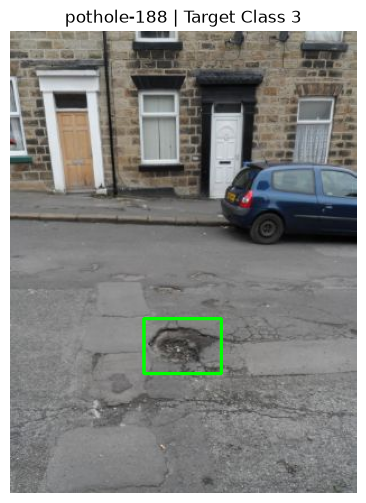

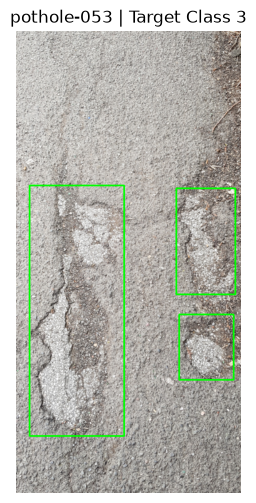

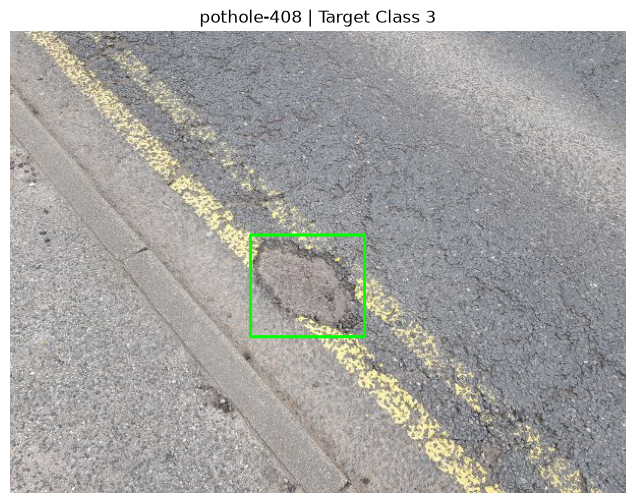

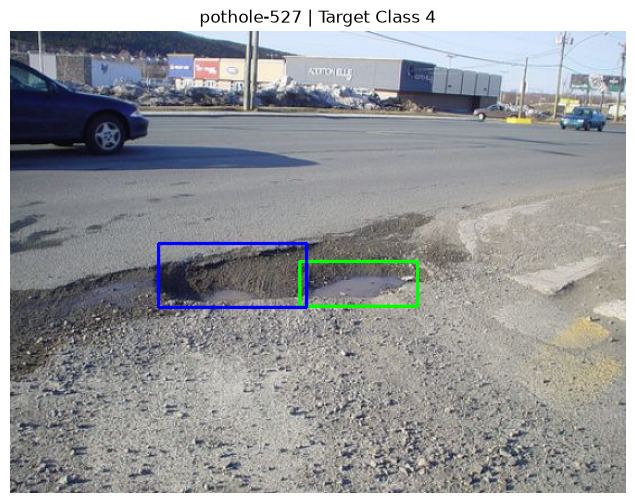

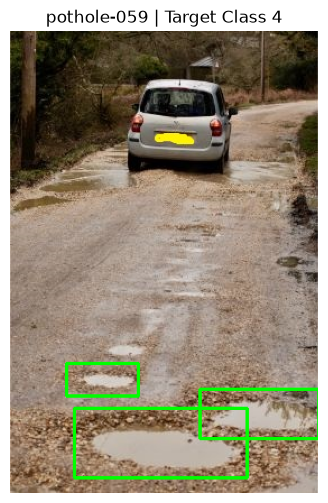

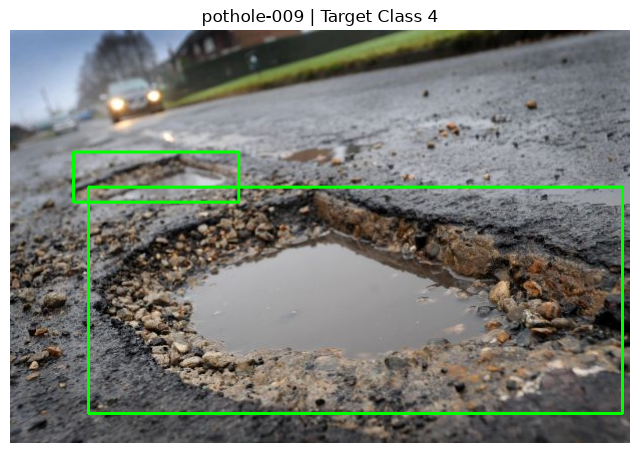

In [43]:
show_yolo_samples(3)
show_yolo_samples(4)

In [44]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset = Path.cwd() / "Datasets" / "Additional_YOLO"

def inspect_annotation(filename):

    name = Path(filename).stem

    image_path = dataset / "images" / f"{name}.jpg"
    label_path = dataset / "labels" / f"{name}.txt"

    image = cv2.imread(str(image_path))

    if image is None:
        print("Image not found:", name)
        return

    height, width = image.shape[:2]

    lines = label_path.read_text().splitlines()

    for index, line in enumerate(lines, start=1):

        cls, xc, yc, w, h = map(float, line.split())

        x1 = int((xc - w/2) * width)
        y1 = int((yc - h/2) * height)
        x2 = int((xc + w/2) * width)
        y2 = int((yc + h/2) * height)

        # Green for ordinary, blue for water-filled
        color = (0, 255, 0) if int(cls) == 3 else (255, 0, 0)

        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

        cv2.putText(
            image,
            f"Line {index}: Class {int(cls)}",
            (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            color,
            2
        )

        print(f"Line {index}: {line}")

    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(name)
    plt.axis("off")
    plt.show()

Line 1: 4 0.556543 0.652913 0.861066 0.548544
Line 2: 4 0.235057 0.356796 0.266559 0.121359


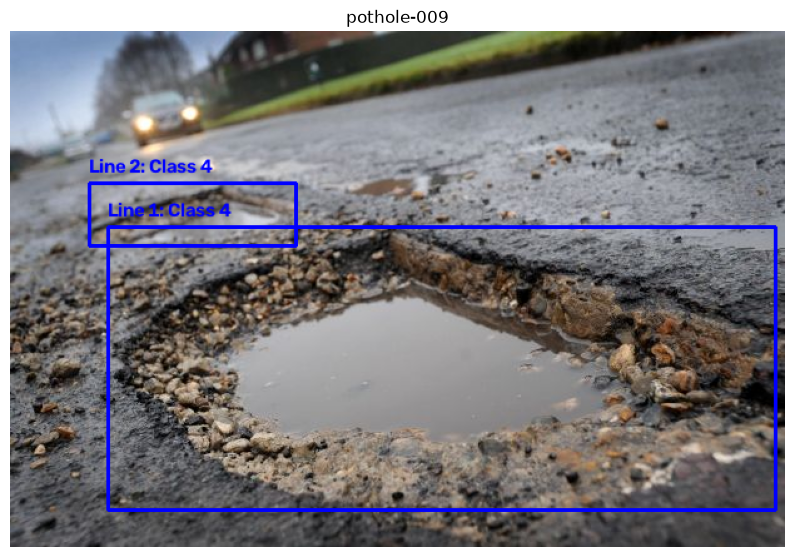

Line 1: 3 0.269133 0.604839 0.420918 0.542184
Line 2: 3 0.845663 0.454715 0.262755 0.229529
Line 3: 3 0.848214 0.683623 0.242347 0.141439


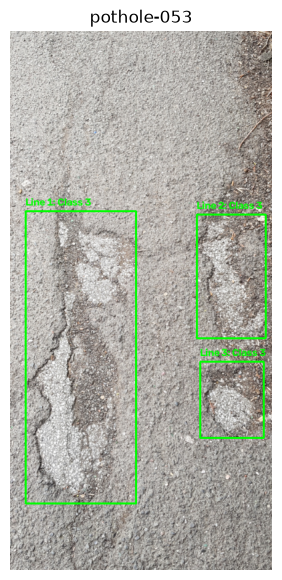

Line 1: 4 0.565574 0.546117 0.191257 0.097087
Line 2: 3 0.360656 0.527913 0.240437 0.138350


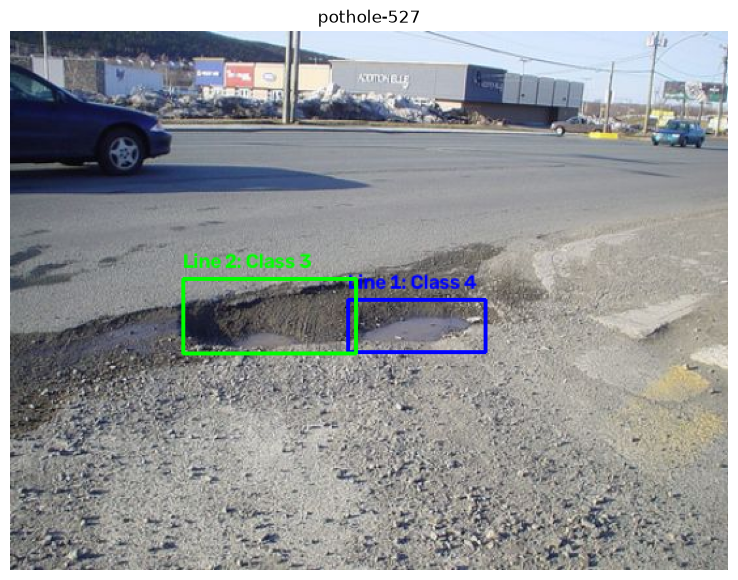

In [45]:
inspect_annotation("pothole-009")
inspect_annotation("pothole-053")
inspect_annotation("pothole-527")

In [46]:
from pathlib import Path
import shutil

project = Path.cwd()

source = project / "Datasets" / "Additional_YOLO"
destination = project / "Datasets" / "Additional_YOLO_REVIEWED"

# Preserve the original converted dataset
assert source.is_dir()
assert not destination.exists(), "Review folder already exists"

shutil.copytree(source, destination)

print("Review copy created successfully!")

Review copy created successfully!


In [35]:
import xml.etree.ElementTree as ET

# Find the problematic XML file
xml_file = next(
    p for p in xml_folder.rglob("*.xml")
    if p.stem.lower() == "pothole-261"
)

tree = ET.parse(xml_file)
root = tree.getroot()

# Get the image dimensions from XML
width = int(root.findtext("size/width"))
height = int(root.findtext("size/height"))

# Get the first annotated object
obj = root.findall("object")[0]
box = obj.find("bndbox")

xmin = float(box.findtext("xmin"))
ymin = float(box.findtext("ymin"))
xmax = float(box.findtext("xmax"))
ymax = float(box.findtext("ymax"))

print("Image width:", width)
print("Image height:", height)

print("\nBounding box:")
print("xmin:", xmin)
print("ymin:", ymin)
print("xmax:", xmax)
print("ymax:", ymax)

print("\nBox width:", xmax - xmin)
print("Box height:", ymax - ymin)

Image width: 392
Image height: 806

Bounding box:
xmin: 1721.0
ymin: 740.0
xmax: 2609.0
ymax: 1660.0

Box width: 888.0
Box height: 920.0


In [47]:
label_file = destination / "labels" / "Pothole-009.txt"

lines = label_file.read_text().splitlines()

assert len(lines) == 2
assert lines[1].strip() == "4 0.235057 0.356796 0.266559 0.121359"

# Remove only the second annotation
del lines[1]

label_file.write_text("\n".join(lines) + "\n")

print("Pothole-009 corrected")

Pothole-009 corrected


In [48]:
from pathlib import Path

reviewed = Path.cwd() / "Datasets" / "Additional_YOLO_REVIEWED"

label_file = reviewed / "labels" / "Pothole-009.txt"

print(label_file.read_text())
print("Remaining boxes:", len(label_file.read_text().splitlines()))

4 0.556543 0.652913 0.861066 0.548544

Remaining boxes: 1


In [49]:
from collections import Counter

class_counts = Counter()

for file in (reviewed / "labels").glob("*.txt"):
    for line in file.read_text().splitlines():
        if line.strip():
            class_id = int(line.split()[0])
            class_counts[class_id] += 1

print("Updated class distribution:", class_counts)

Updated class distribution: Counter({3: 716, 4: 431})


Line 1: 3 0.269133 0.604839 0.420918 0.542184
Line 2: 3 0.845663 0.454715 0.262755 0.229529
Line 3: 3 0.848214 0.683623 0.242347 0.141439


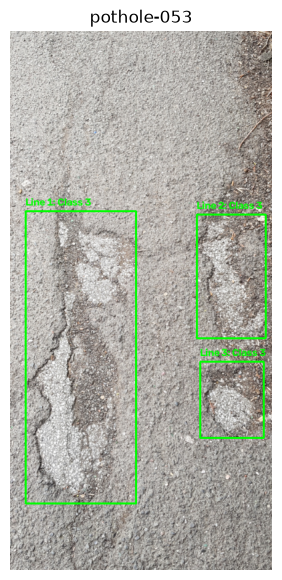

Line 1: 4 0.565574 0.546117 0.191257 0.097087
Line 2: 3 0.360656 0.527913 0.240437 0.138350


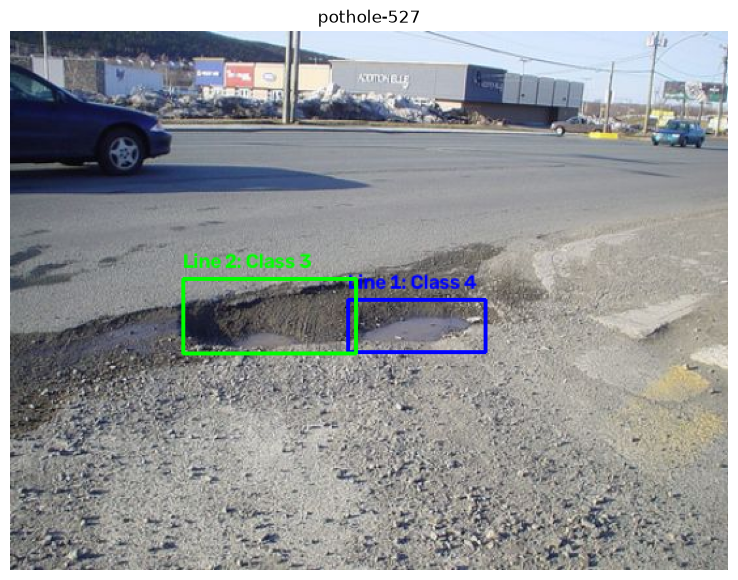

In [50]:
from pathlib import Path

dataset = Path.cwd() / "Datasets" / "Additional_YOLO_REVIEWED"

inspect_annotation("pothole-053")
inspect_annotation("pothole-527")

Line 1: 3 0.499174 0.488987 0.241322 0.528634


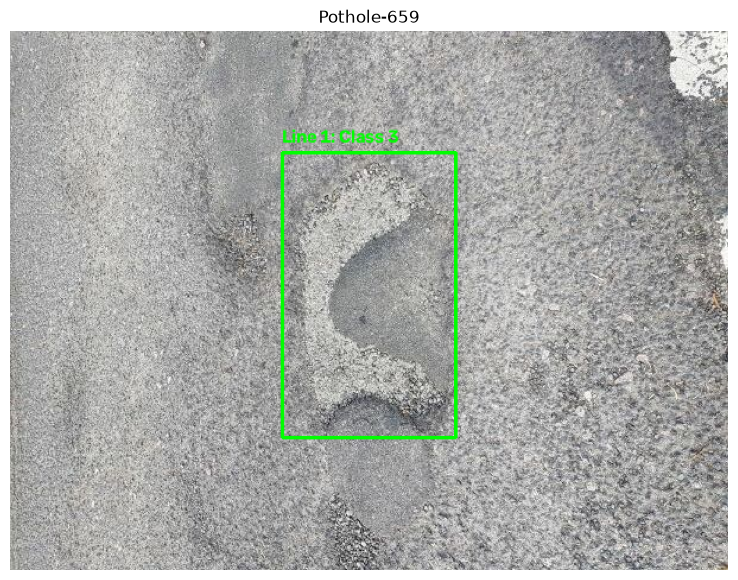

Line 1: 4 0.541262 0.743932 0.474110 0.473301


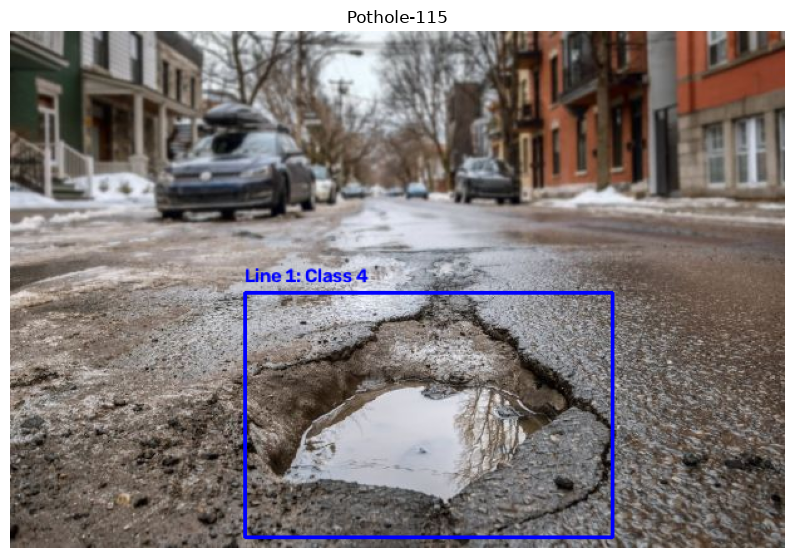

Line 1: 3 0.540816 0.572581 0.693878 0.502481


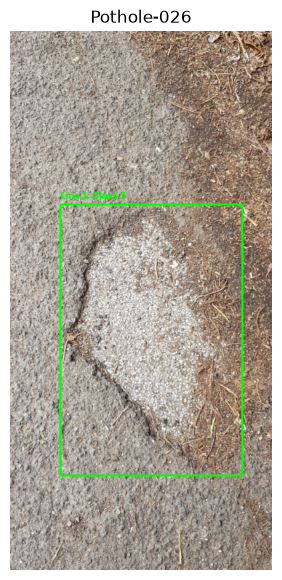

Line 1: 3 0.404337 0.570720 0.670918 0.285360


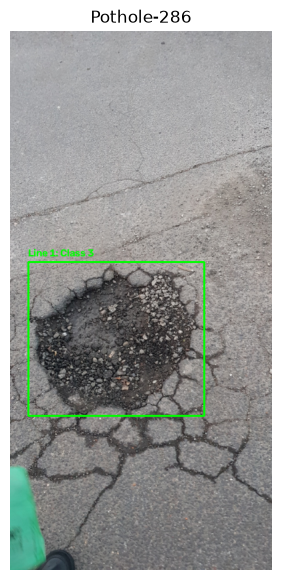

Line 1: 3 0.496173 0.588710 0.737245 0.375931


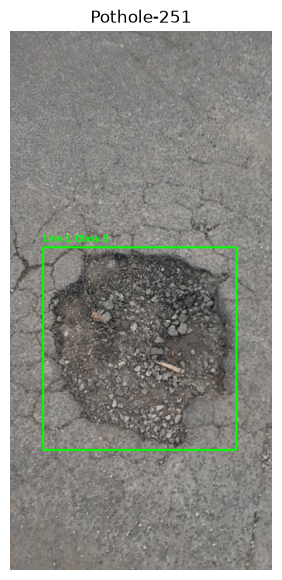

Line 1: 4 0.578479 0.649272 0.474110 0.109223


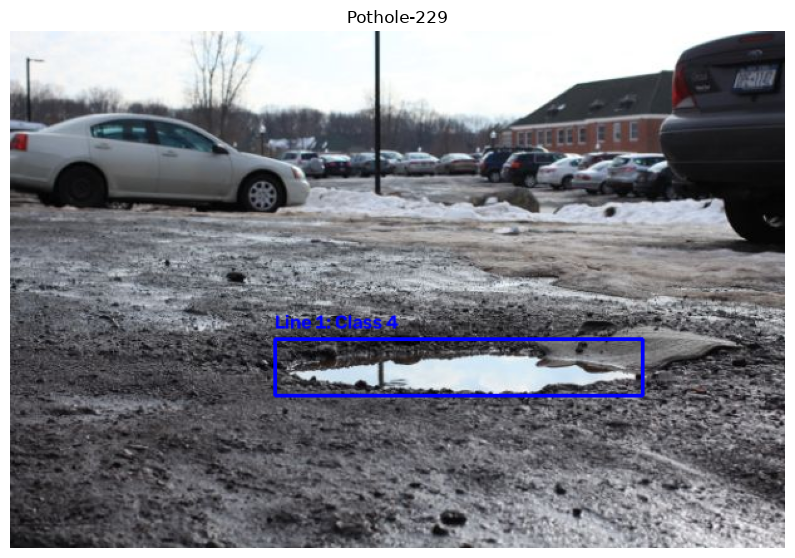

Line 1: 3 0.151370 0.583738 0.264384 0.288835
Line 2: 3 0.484932 0.451456 0.210959 0.262136
Line 3: 3 0.906849 0.456311 0.186301 0.165049


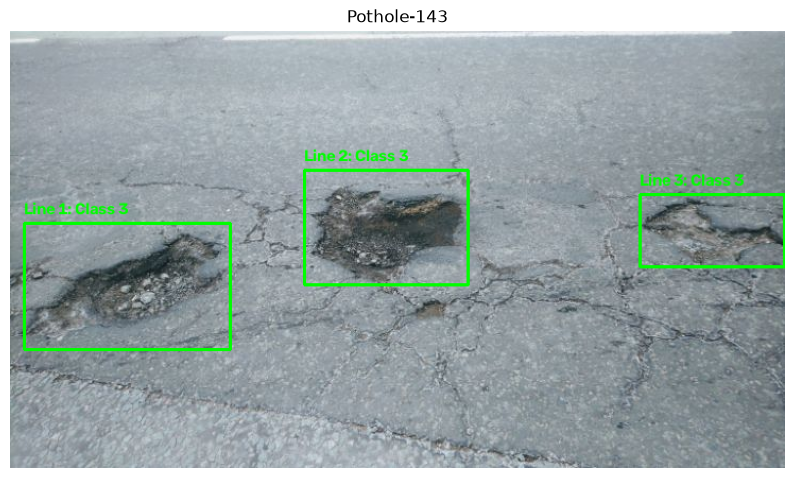

Line 1: 4 0.460000 0.641990 0.920000 0.424757


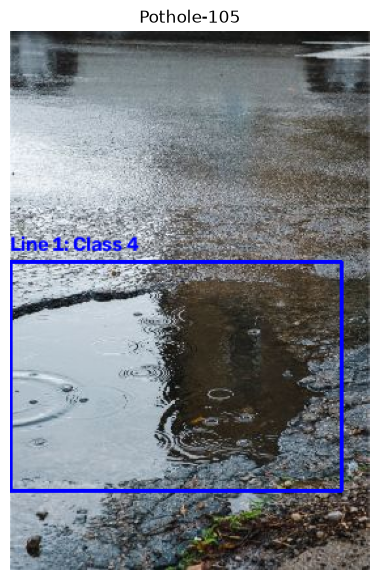

Line 1: 3 0.574890 0.504959 0.488987 0.553719


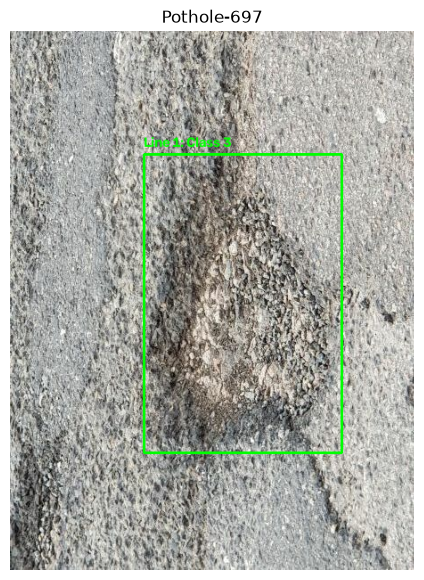

Line 1: 4 0.510018 0.574029 0.783242 0.633495


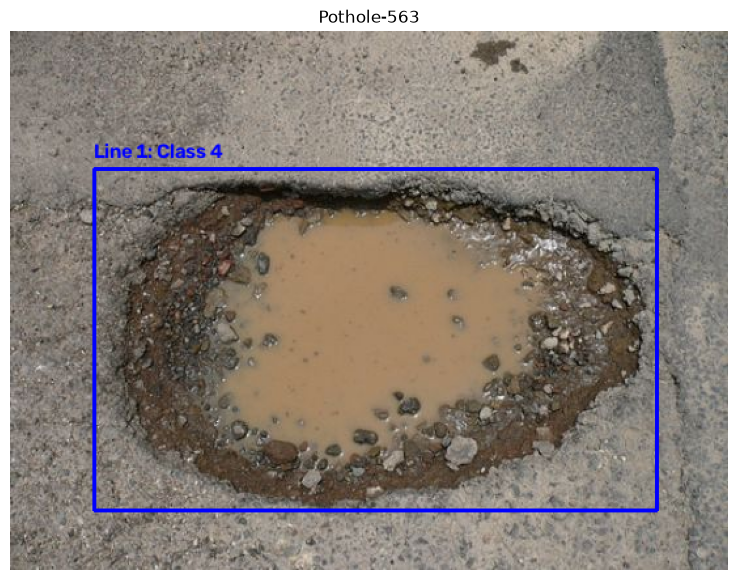

Line 1: 4 0.502427 0.855583 0.600324 0.279126


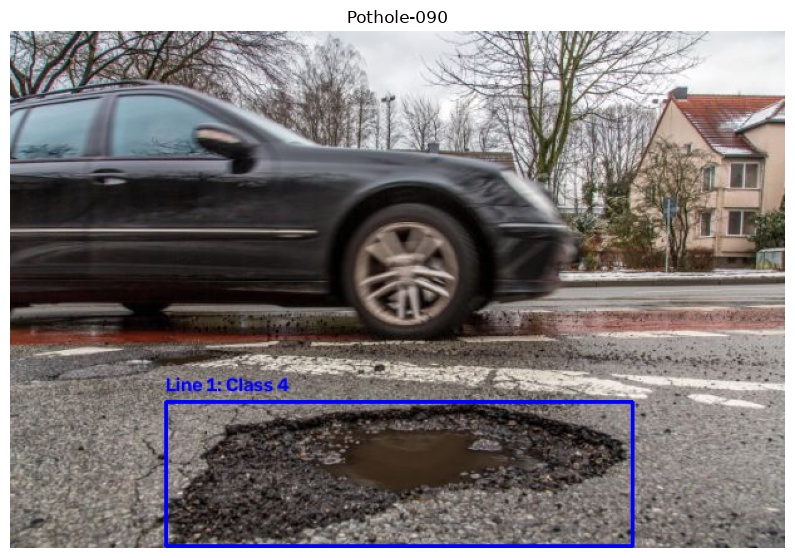

Line 1: 3 0.351117 0.566748 0.253102 0.351942


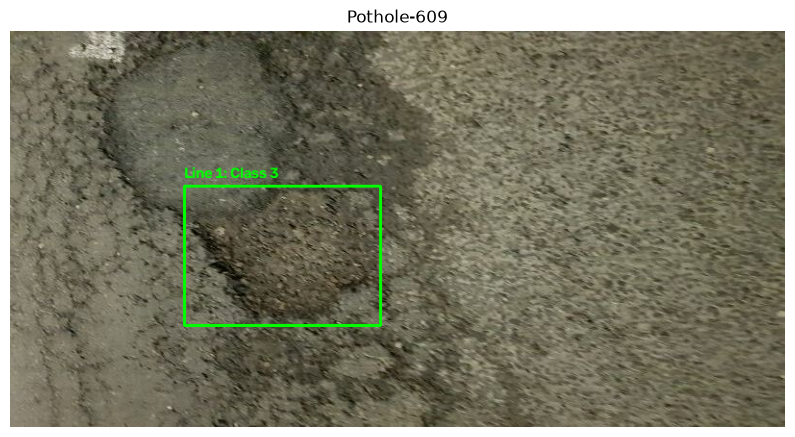

Line 1: 3 0.475410 0.510922 0.823315 0.609223


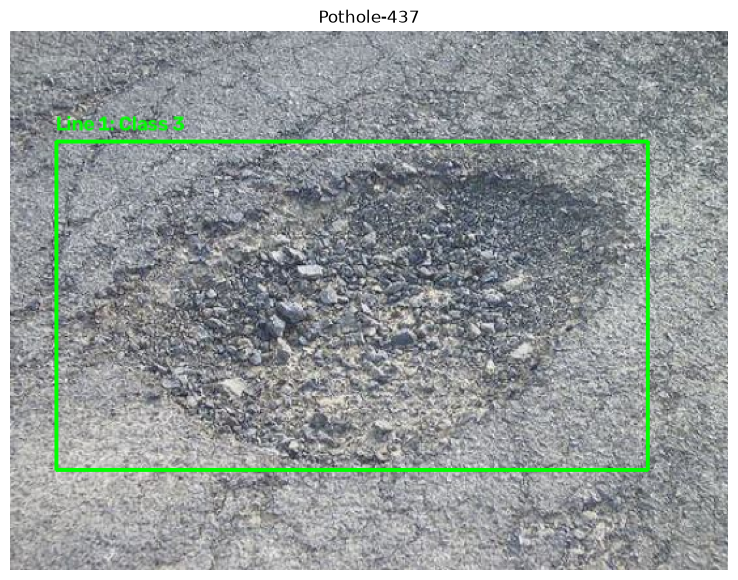

Line 1: 4 0.509709 0.733010 0.456311 0.378641


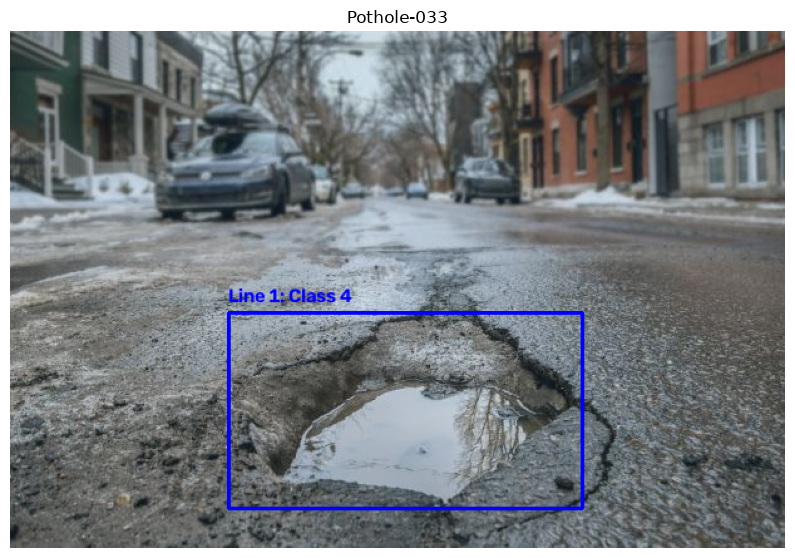

Line 1: 3 0.322704 0.519231 0.645408 0.956576


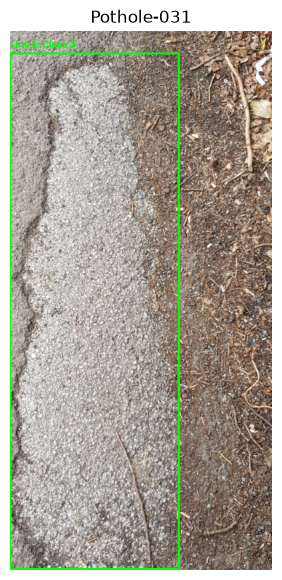

Line 1: 3 0.350765 0.517370 0.701531 0.575682
Line 2: 3 0.292092 0.165633 0.247449 0.107940


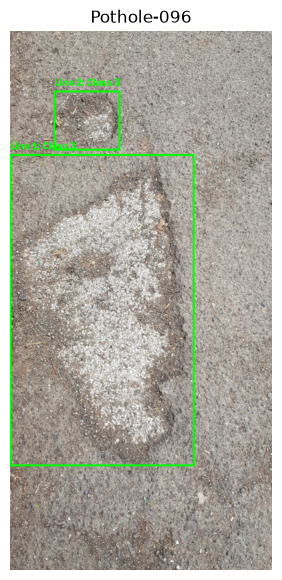

Line 1: 4 0.657767 0.677184 0.315534 0.131068
Line 2: 4 0.330906 0.706311 0.370550 0.184466
Line 3: 4 0.936893 0.561893 0.122977 0.055825
Line 4: 4 0.868932 0.509709 0.106796 0.058252
Line 5: 4 0.618123 0.580097 0.181230 0.067961
Line 6: 4 0.556634 0.498786 0.262136 0.065534
Line 7: 4 0.372168 0.373786 0.139159 0.077670


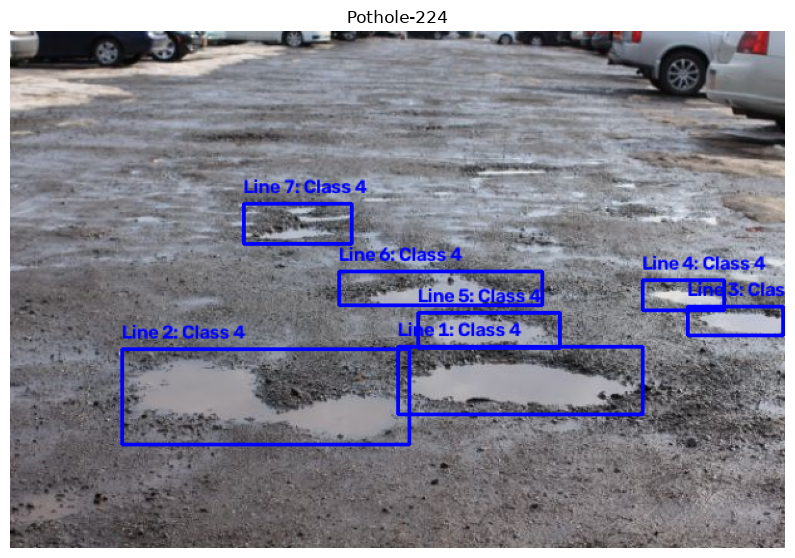

Line 1: 3 0.408925 0.461165 0.479053 0.529126


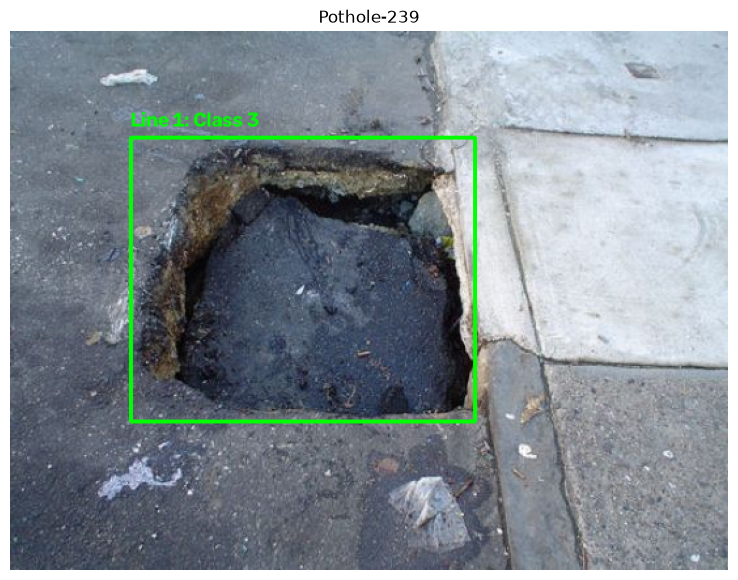

Line 1: 3 0.436248 0.576456 0.406193 0.444175


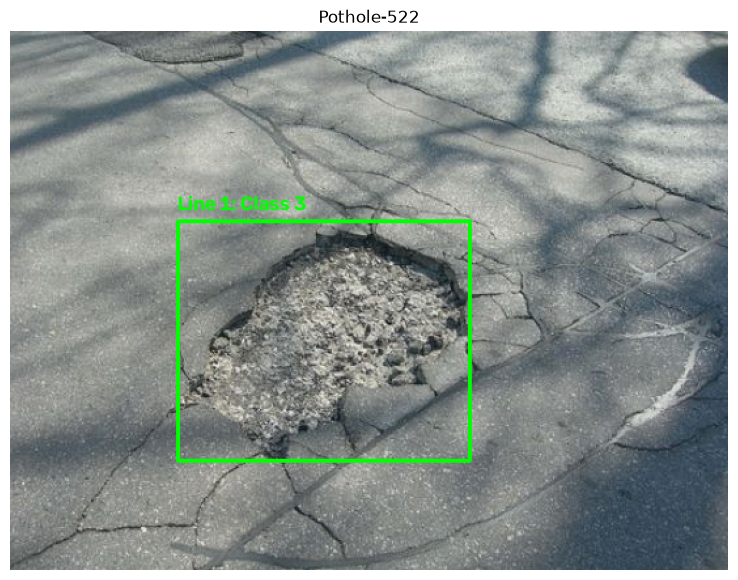

Line 1: 3 0.571340 0.382282 0.162531 0.274272
Line 2: 3 0.635236 0.722087 0.215881 0.371359


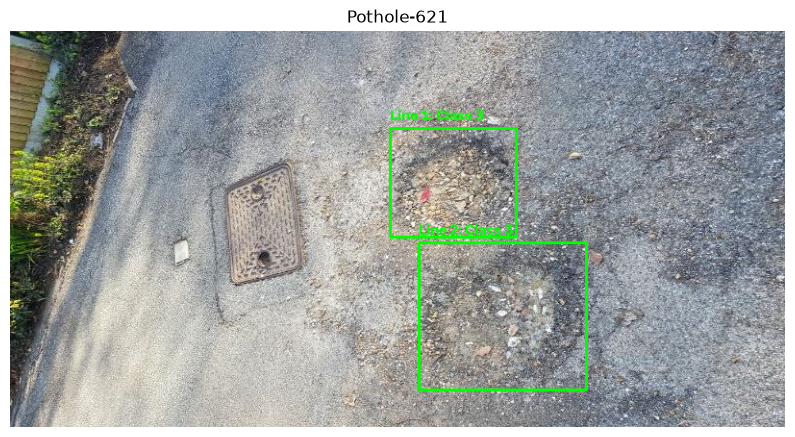

In [51]:
import random

label_folder = dataset / "labels"

label_files = list(label_folder.glob("*.txt"))

random.seed(42)

samples = random.sample(label_files, 20)

for file in samples:
    inspect_annotation(file.stem)

In [52]:
from pathlib import Path
import shutil

project = Path.cwd()

dataset = project / "Datasets" / "Additional_YOLO_REVIEWED"
quarantine = project / "Datasets" / "Additional_QUARANTINE"

questionable = [
    "pothole-609",
    "pothole-031",
    "pothole-659"
]

# Find images and labels
for name in questionable:

    image_matches = [
        p for p in (dataset / "images").iterdir()
        if p.stem.lower() == name
    ]

    label_matches = [
        p for p in (dataset / "labels").glob("*.txt")
        if p.stem.lower() == name
    ]

    if len(image_matches) != 1 or len(label_matches) != 1:
        raise ValueError(f"Missing or duplicate files for {name}")

    image_path = image_matches[0]
    label_path = label_matches[0]

    # Create quarantine directories
    (quarantine / "images").mkdir(parents=True, exist_ok=True)
    (quarantine / "labels").mkdir(parents=True, exist_ok=True)

    # Do not overwrite existing quarantined files
    assert not (quarantine / "images" / image_path.name).exists()
    assert not (quarantine / "labels" / label_path.name).exists()

    shutil.move(str(image_path), str(quarantine / "images" / image_path.name))
    shutil.move(str(label_path), str(quarantine / "labels" / label_path.name))

    print("Quarantined:", name)

Quarantined: pothole-609
Quarantined: pothole-031
Quarantined: pothole-659


In [53]:
from collections import Counter

images = list((dataset / "images").iterdir())
labels = list((dataset / "labels").glob("*.txt"))

counts = Counter()

for label in labels:
    for line in label.read_text().splitlines():
        if line.strip():
            class_id = int(line.split()[0])
            counts[class_id] += 1

print("Images:", len(images))
print("Labels:", len(labels))
print("Class distribution:", counts)

Images: 706
Labels: 706
Class distribution: Counter({3: 713, 4: 431})


In [54]:
from pathlib import Path

project = Path.cwd()
datasets = project / "Datasets"

rdd_images = datasets / "RDD_SPLIT"
rdd_labels = datasets / "RDD_CLEANED"
additional = datasets / "Additional_YOLO_REVIEWED"

# Check dataset folders
print("RDD images:", rdd_images.exists())
print("RDD cleaned labels:", rdd_labels.exists())
print("Additional dataset:", additional.exists())

# Count RDD images and cleaned labels
for split in ["train", "val", "test"]:
    images = list((rdd_images / split / "images").rglob("*.jpg"))
    labels = list((rdd_labels / split / "labels").rglob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} labels")

# Count additional dataset
images = list((additional / "images").glob("*.jpg"))
labels = list((additional / "labels").glob("*.txt"))

print(f"Additional: {len(images)} images, {len(labels)} labels")

RDD images: True
RDD cleaned labels: True
Additional dataset: True
train: 26869 images, 26869 labels
val: 5758 images, 5758 labels
test: 5758 images, 5758 labels
Additional: 706 images, 706 labels


In [55]:
from pathlib import Path
from collections import Counter
import random

project = Path.cwd()
datasets = project / "Datasets"

rdd_images = datasets / "RDD_SPLIT"
rdd_labels = datasets / "RDD_CLEANED"
additional = datasets / "Additional_YOLO_REVIEWED"

extensions = {".jpg", ".jpeg", ".png"}

# Match images with labels
def collect_pairs(image_folder, label_folder):

    images = {}
    labels = {}

    for p in image_folder.rglob("*"):
        if p.is_file() and p.suffix.lower() in extensions:
            key = p.stem.lower()
            if key in images:
                raise ValueError(f"Duplicate image name: {key}")
            images[key] = p

    for p in label_folder.rglob("*.txt"):
        key = p.stem.lower()
        if key in labels:
            raise ValueError(f"Duplicate label name: {key}")
        labels[key] = p

    if set(images) != set(labels):
        raise ValueError(
            f"Unmatched image/label files in {image_folder}"
        )

    return [(images[k], labels[k]) for k in sorted(images)]


# Create a manifest of files to copy
manifest = []

# RDD2022 — preserve existing splits
for split in ["train", "val", "test"]:

    pairs = collect_pairs(
        rdd_images / split / "images",
        rdd_labels / split / "labels"
    )

    for image, label in pairs:
        manifest.append((split, "rdd", image, label))

    print(f"RDD {split}: {len(pairs)} images")


# Additional dataset
additional_pairs = collect_pairs(
    additional / "images",
    additional / "labels"
)

print("Additional images:", len(additional_pairs))

# Separate images containing water-filled potholes
groups = {True: [], False: []}

for image, label in additional_pairs:

    classes = {
        int(line.split()[0])
        for line in label.read_text().splitlines()
        if line.strip()
    }

    if not classes or not classes.issubset({3, 4}):
        raise ValueError(f"Unexpected classes: {label.name}")

    groups[4 in classes].append((image, label))


# Deterministic 70 / 15 / 15 split
rng = random.Random(42)

for group in groups.values():

    rng.shuffle(group)

    n = len(group)
    train_end = round(n * 0.70)
    val_end = train_end + round(n * 0.15)

    assignments = [
        ("train", group[:train_end]),
        ("val", group[train_end:val_end]),
        ("test", group[val_end:])
    ]

    for split, pairs in assignments:
        for image, label in pairs:
            manifest.append(
                (split, "additional", image, label)
            )


# Check planned totals
counts = Counter(item[0] for item in manifest)

print("\nFinal planned image counts:")
print(counts)
print("Total:", len(manifest))

assert len(manifest) == 39091

RDD train: 26869 images
RDD val: 5758 images
RDD test: 5758 images
Additional images: 706

Final planned image counts:
Counter({'train': 27364, 'val': 5864, 'test': 5863})
Total: 39091


In [56]:
import hashlib
from collections import defaultdict

# Group images by file size first
size_groups = defaultdict(list)

for split, source, image, label in manifest:
    size_groups[image.stat().st_size].append(
        (split, image)
    )

# Hash only images with matching sizes
hash_groups = defaultdict(list)

for group in size_groups.values():

    if len(group) < 2:
        continue

    for split, image in group:

        digest = hashlib.sha256(
            image.read_bytes()
        ).hexdigest()

        hash_groups[digest].append((split, image))


# Identify identical files in different splits
leakage = []
same_split_duplicates = []

for group in hash_groups.values():

    if len(group) < 2:
        continue

    splits = {item[0] for item in group}

    if len(splits) > 1:
        leakage.append(group)
    else:
        same_split_duplicates.append(group)


print("Duplicate groups across splits:", len(leakage))
print("Duplicate groups within splits:",
      len(same_split_duplicates))

for group in leakage[:5]:
    print("\nDuplicate group:")
    for split, image in group:
        print(split, image.name)

if leakage:
    raise RuntimeError(
        "Exact duplicate images cross splits. "
        "Resolve them before merging."
    )

Duplicate groups across splits: 17
Duplicate groups within splits: 20

Duplicate group:
train Pothole-013.jpg
test Pothole-010.jpg

Duplicate group:
train Pothole-132.jpg
test Pothole-098.jpg

Duplicate group:
train Pothole-102.jpg
val Pothole-043.jpg
val Pothole-060.jpg

Duplicate group:
train Pothole-080.jpg
val Pothole-215.jpg

Duplicate group:
train Pothole-044.jpg
val Pothole-048.jpg


RuntimeError: Exact duplicate images cross splits. Resolve them before merging.

In [57]:
# Look up the label file for each image
image_lookup = {
    image.resolve(): (split, source, label)
    for split, source, image, label in manifest
}

duplicate_groups = leakage + same_split_duplicates

identical_labels = 0
different_labels = 0

problematic_groups = []

for group in duplicate_groups:

    records = []

    for split, image in group:

        _, source, label = image_lookup[image.resolve()]

        # Read and standardize annotation lines
        lines = tuple(sorted(
            line.strip()
            for line in label.read_text().splitlines()
            if line.strip()
        ))

        records.append({
            "split": split,
            "image": image.name,
            "label": label,
            "annotations": lines
        })

    # Compare all annotation sets within this group
    unique_annotations = {
        record["annotations"]
        for record in records
    }

    if len(unique_annotations) == 1:
        identical_labels += 1
    else:
        different_labels += 1
        problematic_groups.append(records)

print("Duplicate groups:", len(duplicate_groups))
print("Groups with identical labels:", identical_labels)
print("Groups with different labels:", different_labels)

print("\nExamples of differing annotations:")

for group in problematic_groups[:5]:

    print("\n--- Duplicate group ---")

    for record in group:
        print(record["split"], record["image"])
        print("Annotations:", len(record["annotations"]))
        print(record["annotations"][:3])

Duplicate groups: 37
Groups with identical labels: 0
Groups with different labels: 37

Examples of differing annotations:

--- Duplicate group ---
train Pothole-013.jpg
Annotations: 1
('4 0.434677 0.544903 0.375806 0.235437',)
test Pothole-010.jpg
Annotations: 1
('4 0.433065 0.548544 0.375806 0.237864',)

--- Duplicate group ---
train Pothole-132.jpg
Annotations: 1
('3 0.488673 0.655340 0.359223 0.140777',)
test Pothole-098.jpg
Annotations: 1
('3 0.483010 0.656553 0.354369 0.157767',)

--- Duplicate group ---
train Pothole-102.jpg
Annotations: 1
('3 0.551002 0.553398 0.581056 0.407767',)
val Pothole-043.jpg
Annotations: 1
('3 0.535519 0.513350 0.542805 0.468447',)
val Pothole-060.jpg
Annotations: 1
('3 0.540984 0.490291 0.564663 0.412621',)

--- Duplicate group ---
train Pothole-080.jpg
Annotations: 1
('3 0.507273 0.824029 0.570909 0.167476',)
val Pothole-215.jpg
Annotations: 1
('3 0.500000 0.826456 0.549091 0.167476',)

--- Duplicate group ---
train Pothole-044.jpg
Annotations: 1
('4 

In [58]:
from collections import Counter

# 1. Read YOLO bounding boxes
def read_boxes(label_path):

    boxes = []

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        cls, xc, yc, w, h = map(float, line.split())

        boxes.append((
            int(cls),
            xc - w/2,
            yc - h/2,
            xc + w/2,
            yc + h/2
        ))

    return boxes


# 2. Calculate IoU
def box_iou(a, b):

    x1 = max(a[1], b[1])
    y1 = max(a[2], b[2])
    x2 = min(a[3], b[3])
    y2 = min(a[4], b[4])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area_a = max(0, a[3]-a[1]) * max(0, a[4]-a[2])
    area_b = max(0, b[3]-b[1]) * max(0, b[4]-b[2])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0


# 3. Match objects by class and overlap
def compare_annotations(boxes_a, boxes_b):

    if len(boxes_a) != len(boxes_b):
        return None

    candidates = []

    for i, a in enumerate(boxes_a):
        for j, b in enumerate(boxes_b):

            if a[0] == b[0]:
                candidates.append((box_iou(a, b), i, j))

    candidates.sort(reverse=True)

    used_a = set()
    used_b = set()
    scores = []

    for score, i, j in candidates:

        if i not in used_a and j not in used_b:
            used_a.add(i)
            used_b.add(j)
            scores.append(score)

    if len(scores) != len(boxes_a):
        return None

    return min(scores) if scores else 1.0


# 4. Compare all duplicate groups
lookup = {
    image.resolve(): (split, source, label)
    for split, source, image, label in manifest
}

duplicate_groups = leakage + same_split_duplicates

results = []

for group_number, group in enumerate(duplicate_groups, 1):

    # Prefer training copy, then validation, then test
    sorted_group = sorted(
        group,
        key=lambda item: (
            {"train": 0, "val": 1, "test": 2}[item[0]],
            item[1].name
        )
    )

    reference_image = sorted_group[0][1]
    reference_label = lookup[reference_image.resolve()][2]

    reference_boxes = read_boxes(reference_label)

    scores = []

    for split, image in sorted_group[1:]:

        label = lookup[image.resolve()][2]
        score = compare_annotations(
            reference_boxes,
            read_boxes(label)
        )

        scores.append(score)

    # A threshold for prioritizing manual review
    safe_candidate = all(
        score is not None and score >= 0.85
        for score in scores
    )

    results.append({
        "group": group_number,
        "reference": reference_image.name,
        "duplicates": len(group),
        "minimum_iou": (
            min(scores) if all(s is not None for s in scores)
            else None
        ),
        "status": "Close match" if safe_candidate else "Review"
    })


# 5. Print summary
import pandas as pd

df_duplicates = pd.DataFrame(results)

print("Total duplicate groups:", len(results))
print("\nComparison results:")
print(df_duplicates["status"].value_counts())

display(df_duplicates)

Total duplicate groups: 37

Comparison results:
status
Close match    19
Review         18
Name: count, dtype: int64


,group,reference,duplicates,minimum_iou,status
0,1,Pothole-013.jpg,2,0.961536,Close match
1,2,Pothole-132.jpg,2,0.866510,Close match
2,3,Pothole-102.jpg,3,0.711488,Review
3,4,Pothole-080.jpg,2,0.934817,Close match
4,5,Pothole-044.jpg,2,0.969810,Close match
5,6,Pothole-087.jpg,2,NaN,Review
6,7,Pothole-090.jpg,4,0.914916,Close match
7,8,Pothole-151.jpg,3,NaN,Review
8,9,Pothole-180.jpg,4,0.913179,Close match
9,10,Pothole-190.jpg,2,0.936535,Close match


In [59]:
import cv2
import matplotlib.pyplot as plt

def inspect_duplicate_group(group_number):

    group = duplicate_groups[group_number - 1]

    fig, axes = plt.subplots(
        1,
        len(group),
        figsize=(6 * len(group), 6),
        squeeze=False
    )

    for ax, (split, image_path) in zip(axes[0], group):

        # Find the corresponding annotation
        _, source, label_path = lookup[image_path.resolve()]

        image = cv2.imread(str(image_path))

        if image is None:
            print("Cannot read:", image_path)
            continue

        height, width = image.shape[:2]

        boxes = read_boxes(label_path)

        # Draw bounding boxes
        for index, (cls, x1, y1, x2, y2) in enumerate(boxes, 1):

            pt1 = (int(x1 * width), int(y1 * height))
            pt2 = (int(x2 * width), int(y2 * height))

            color = (0, 255, 0) if cls == 3 else (255, 0, 0)

            cv2.rectangle(image, pt1, pt2, color, 2)

            cv2.putText(
                image,
                f"{index}: Class {cls}",
                (pt1[0], max(20, pt1[1] - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                color,
                2
            )

        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

        ax.set_title(
            f"{image_path.name}\n"
            f"Split: {split} | Source: {source}\n"
            f"Objects: {len(boxes)}"
        )

        ax.axis("off")

    plt.suptitle(f"Duplicate Group {group_number}")
    plt.tight_layout()
    plt.show()
    plt.close()

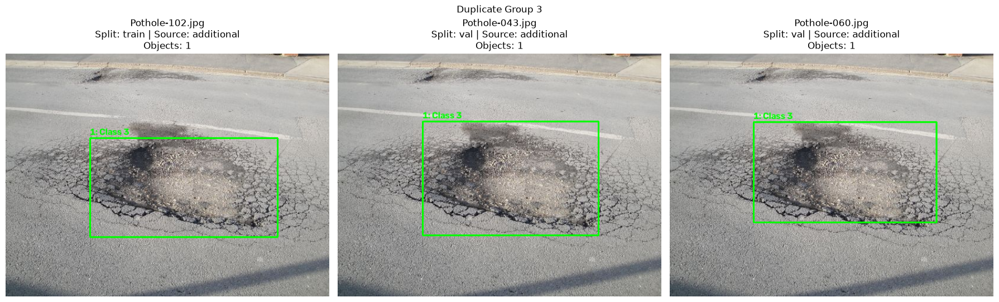

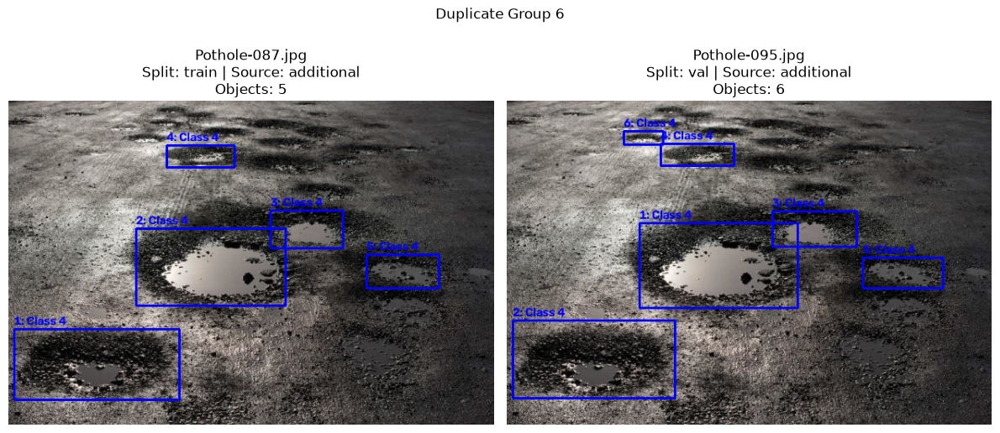

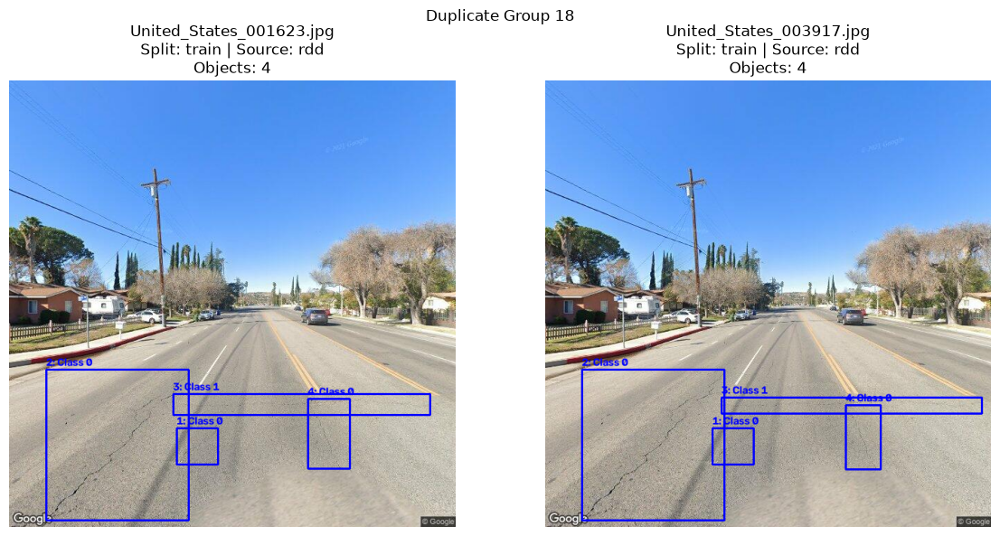

In [60]:
inspect_duplicate_group(3)
inspect_duplicate_group(6)
inspect_duplicate_group(18)

In [61]:
import pandas as pd
import hashlib
from pathlib import Path

records = []
split_order = {"train": 0, "val": 1, "test": 2}

for group_number, group in enumerate(duplicate_groups, 1):

    # Put training copies first
    ordered = sorted(
        group,
        key=lambda item: (
            split_order[item[0]],
            str(item[1]).lower()
        )
    )

    status = df_duplicates.loc[
        df_duplicates["group"] == group_number,
        "status"
    ].iloc[0]

    choices = " | ".join(
        f"{i}: {split}/{image.name}"
        for i, (split, image) in enumerate(ordered)
    )

    image_hash = hashlib.sha256(
        ordered[0][1].read_bytes()
    ).hexdigest()

    records.append({
        "group": group_number,
        "image_hash": image_hash,
        "status": status,
        "choices": choices,
        "keep_index": 0 if status == "Close match" else None,
        "notes": ""
    })

review_df = pd.DataFrame(records)

review_csv = Path.cwd() / "duplicate_review.csv"

if not review_csv.exists():
    review_df.to_csv(review_csv, index=False)
    print("Duplicate review CSV created!")
else:
    print("Existing review CSV preserved.")

print("Duplicate groups:", len(review_df))
display(review_df.head(10))

Duplicate review CSV created!
Duplicate groups: 37


,group,image_hash,status,choices,keep_index,notes
0,1,feb9bb3e1b4e2fb5cf1bf2fd7a817ff102c07ce7cbd53c...,Close match,0: train/Pothole-013.jpg | 1: test/Pothole-010...,0.0,
1,2,e81651bc764812b8ef54f856e998c124ea34eb128c1501...,Close match,0: train/Pothole-132.jpg | 1: test/Pothole-098...,0.0,
2,3,7b89e8ec55010db9c0e77e7e38e6d2de7094c90f17090f...,Review,0: train/Pothole-102.jpg | 1: val/Pothole-043....,NaN,
3,4,f2a55236c91cd48962edb2b6f962466610ef6d44766a26...,Close match,0: train/Pothole-080.jpg | 1: val/Pothole-215.jpg,0.0,
4,5,31a28b2854f42ecfdd2926a109a6477a09c4496a967d39...,Close match,0: train/Pothole-044.jpg | 1: val/Pothole-048.jpg,0.0,
5,6,98b85cb7d8afb8f6afbd65b240856766601f6c307f2563...,Review,0: train/Pothole-087.jpg | 1: val/Pothole-095.jpg,NaN,
6,7,529085eaba5c1eac3a632b5b4bcf5aa25d7bf1ca9e9a11...,Close match,0: train/Pothole-090.jpg | 1: train/Pothole-14...,0.0,
7,8,b5ae3d3b320e972027d00b886dae29851493e0fa0a304b...,Review,0: train/Pothole-151.jpg | 1: val/Pothole-073....,NaN,
8,9,abc54098fd9d3b1644725f5a2df20e02c0711b737ef313...,Close match,0: train/Pothole-180.jpg | 1: train/Pothole-19...,0.0,
9,10,86d0c91099d4e697213b263b816aa766bfd92c0629e4ff...,Close match,0: train/Pothole-190.jpg | 1: test/Pothole-045...,0.0,


In [62]:
import pandas as pd
from pathlib import Path

review_csv = Path.cwd() / "duplicate_review.csv"

decisions = pd.read_csv(review_csv)

# Group 3: Keep Pothole-102.jpg
decisions.loc[
    decisions["group"] == 3,
    "keep_index"
] = 0

# Group 18: Keep UnitedStates_001623.jpg
decisions.loc[
    decisions["group"] == 18,
    "keep_index"
] = 0

# Save our decisions
decisions.to_csv(review_csv, index=False)

display(
    decisions[
        decisions["group"].isin([3, 6, 18])
    ][["group", "choices", "keep_index"]]
)

,group,choices,keep_index
2,3,0: train/Pothole-102.jpg | 1: val/Pothole-043....,0.0
5,6,0: train/Pothole-087.jpg | 1: val/Pothole-095.jpg,NaN
17,18,0: train/United_States_001623.jpg | 1: train/U...,0.0


Total annotations: 6


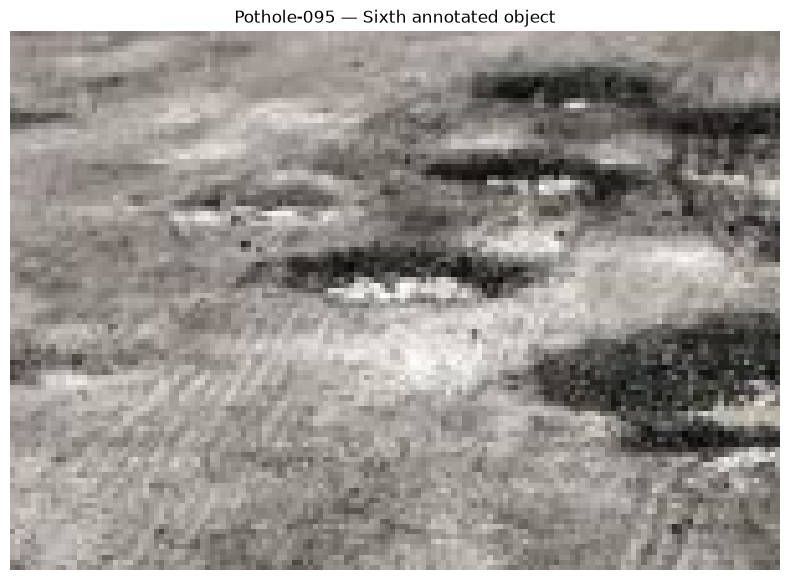

In [63]:
import cv2
import matplotlib.pyplot as plt

dataset = Path.cwd() / "Datasets" / "Additional_YOLO_REVIEWED"

image_path = dataset / "images" / "Pothole-095.jpg"
label_path = dataset / "labels" / "Pothole-095.txt"

image = cv2.imread(str(image_path))

assert image is not None

height, width = image.shape[:2]

# Read the sixth bounding box
lines = label_path.read_text().splitlines()

print("Total annotations:", len(lines))

cls, xc, yc, w, h = map(float, lines[5].split())

# Convert YOLO coordinates into pixels
x1 = int((xc - w/2) * width)
y1 = int((yc - h/2) * height)
x2 = int((xc + w/2) * width)
y2 = int((yc + h/2) * height)

# Add space around the object
margin = 50

x1 = max(0, x1 - margin)
y1 = max(0, y1 - margin)
x2 = min(width, x2 + margin)
y2 = min(height, y2 + margin)

cropped = image[y1:y2, x1:x2]

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
plt.title("Pothole-095 — Sixth annotated object")
plt.axis("off")
plt.show()

In [64]:
decisions = pd.read_csv(review_csv)

# Change to 1 if Pothole-095 is the better annotation
chosen_index = 0

decisions.loc[
    decisions["group"] == 6,
    "keep_index"
] = chosen_index

decisions.to_csv(review_csv, index=False)

print("Group 6 decision saved!")

Group 6 decision saved!


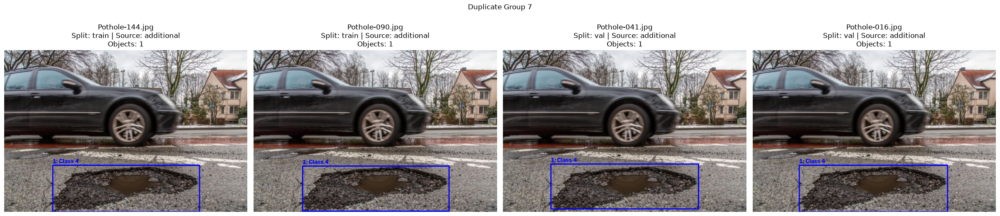

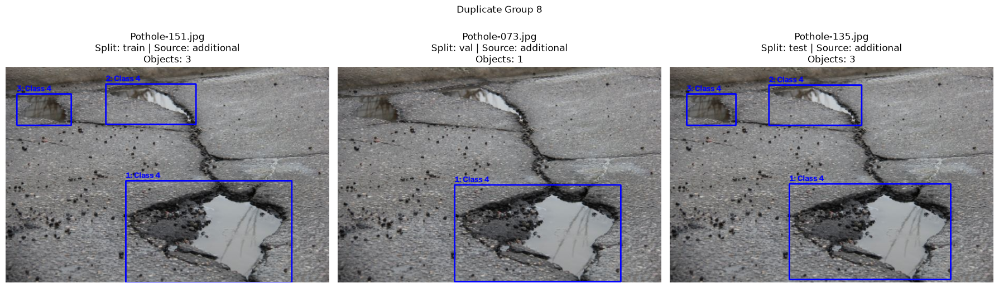

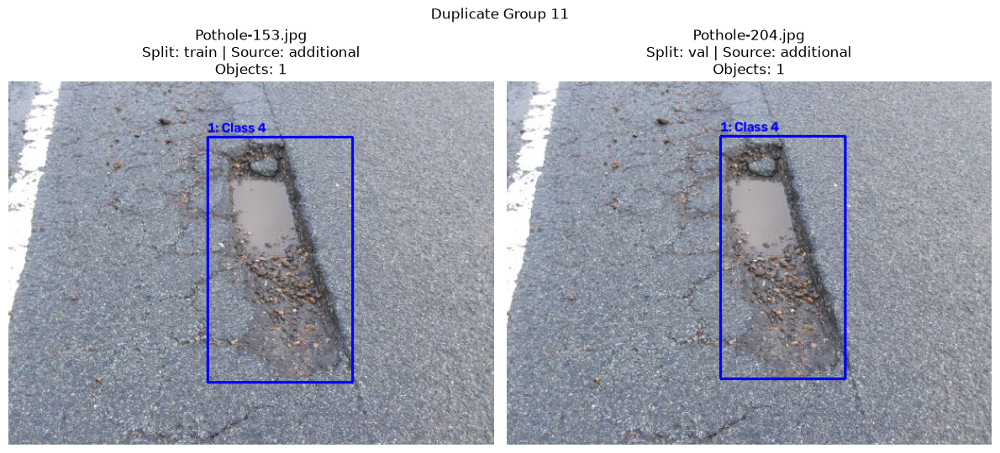

In [70]:
inspect_duplicate_group(7)
inspect_duplicate_group(8)
inspect_duplicate_group(11)

In [66]:
decisions = pd.read_csv(review_csv)

print("Total groups:", len(decisions))

print(
    "Groups with decisions:",
    decisions["keep_index"].notna().sum()
)

print(
    "Groups still needing review:",
    decisions["keep_index"].isna().sum()
)

display(
    decisions[
        decisions["keep_index"].isna()
    ][["group", "choices", "status"]]
)

Total groups: 37
Groups with decisions: 22
Groups still needing review: 15


,group,choices,status
7,8,0: train/Pothole-151.jpg | 1: val/Pothole-073....,Review
10,11,0: train/Pothole-153.jpg | 1: val/Pothole-204.jpg,Review
11,12,0: train/Pothole-219.jpg | 1: test/Pothole-149...,Review
13,14,0: train/Pothole-112.jpg | 1: train/Pothole-22...,Review
16,17,0: train/Pothole-114.jpg | 1: train/Pothole-11...,Review
18,19,0: train/Pothole-018.jpg | 1: train/Pothole-03...,Review
22,23,0: train/Pothole-220.jpg | 1: train/Pothole-23...,Review
23,24,0: train/Pothole-017.jpg | 1: train/Pothole-12...,Review
25,26,0: train/Pothole-062.jpg | 1: train/Pothole-13...,Review
28,29,0: train/Pothole-198.jpg | 1: train/Pothole-23...,Review


In [67]:
import pandas as pd
from pathlib import Path

review_csv = Path.cwd() / "duplicate_review.csv"

decisions = pd.read_csv(review_csv)

# Confirm index 0 represents Pothole-087
group6 = decisions.loc[decisions["group"] == 6]
print(group6["choices"].iloc[0])

assert "0: train/Pothole-087.jpg" in group6["choices"].iloc[0]

# Keep Pothole-087
decisions.loc[
    decisions["group"] == 6,
    "keep_index"
] = 0

decisions.to_csv(review_csv, index=False)

print("Group 6 decision saved!")

0: train/Pothole-087.jpg | 1: val/Pothole-095.jpg
Group 6 decision saved!


In [68]:
display(
    decisions.loc[
        decisions["group"].isin([3, 6, 18]),
        ["group", "choices", "keep_index"]
    ]
)

,group,choices,keep_index
2,3,0: train/Pothole-102.jpg | 1: val/Pothole-043....,0.0
5,6,0: train/Pothole-087.jpg | 1: val/Pothole-095.jpg,0.0
17,18,0: train/United_States_001623.jpg | 1: train/U...,0.0


In [69]:
print(
    "Groups remaining:",
    decisions["keep_index"].isna().sum()
)

Groups remaining: 15


In [71]:
import pandas as pd
from pathlib import Path

review_csv = Path.cwd() / "duplicate_review.csv"
decisions = pd.read_csv(review_csv)

display(
    decisions.loc[
        decisions["group"].isin([7, 8, 11]),
        ["group", "choices", "keep_index"]
    ]
)

,group,choices,keep_index
6,7,0: train/Pothole-090.jpg | 1: train/Pothole-14...,0.0
7,8,0: train/Pothole-151.jpg | 1: val/Pothole-073....,NaN
10,11,0: train/Pothole-153.jpg | 1: val/Pothole-204.jpg,NaN


In [72]:
decisions.loc[decisions["group"] == 7, "keep_index"] = 0
decisions.loc[decisions["group"] == 8, "keep_index"] = 0
decisions.loc[decisions["group"] == 11, "keep_index"] = 0

decisions.to_csv(review_csv, index=False)

display(
    decisions.loc[
        decisions["group"].isin([7, 8, 11]),
        ["group", "choices", "keep_index"]
    ]
)

,group,choices,keep_index
6,7,0: train/Pothole-090.jpg | 1: train/Pothole-14...,0.0
7,8,0: train/Pothole-151.jpg | 1: val/Pothole-073....,0.0
10,11,0: train/Pothole-153.jpg | 1: val/Pothole-204.jpg,0.0


In [73]:
import pandas as pd
from pathlib import Path

review_csv = Path.cwd() / "duplicate_review.csv"

decisions = pd.read_csv(review_csv)

print("Total duplicate groups:", len(decisions))
print("Decisions saved:", decisions["keep_index"].notna().sum())
print("Groups remaining:", decisions["keep_index"].isna().sum())

pending = decisions[decisions["keep_index"].isna()]

display(pending[["group", "choices", "status"]])

Total duplicate groups: 37
Decisions saved: 24
Groups remaining: 13


,group,choices,status
11,12,0: train/Pothole-219.jpg | 1: test/Pothole-149...,Review
13,14,0: train/Pothole-112.jpg | 1: train/Pothole-22...,Review
16,17,0: train/Pothole-114.jpg | 1: train/Pothole-11...,Review
18,19,0: train/Pothole-018.jpg | 1: train/Pothole-03...,Review
22,23,0: train/Pothole-220.jpg | 1: train/Pothole-23...,Review
23,24,0: train/Pothole-017.jpg | 1: train/Pothole-12...,Review
25,26,0: train/Pothole-062.jpg | 1: train/Pothole-13...,Review
28,29,0: train/Pothole-198.jpg | 1: train/Pothole-23...,Review
32,33,0: train/Pothole-034.jpg | 1: train/Pothole-06...,Review
33,34,0: train/Pothole-130.jpg | 1: train/Pothole-14...,Review


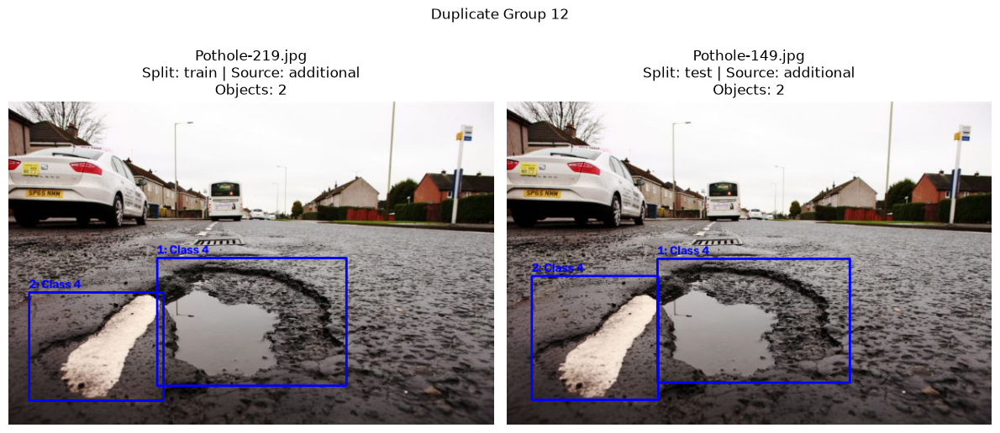

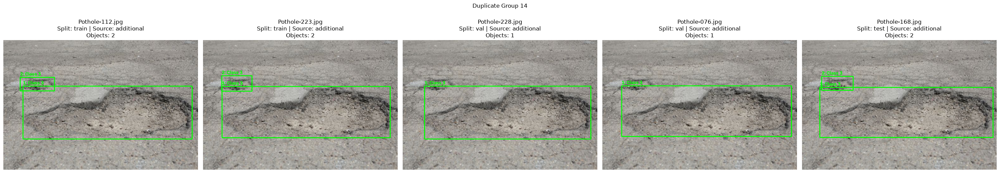

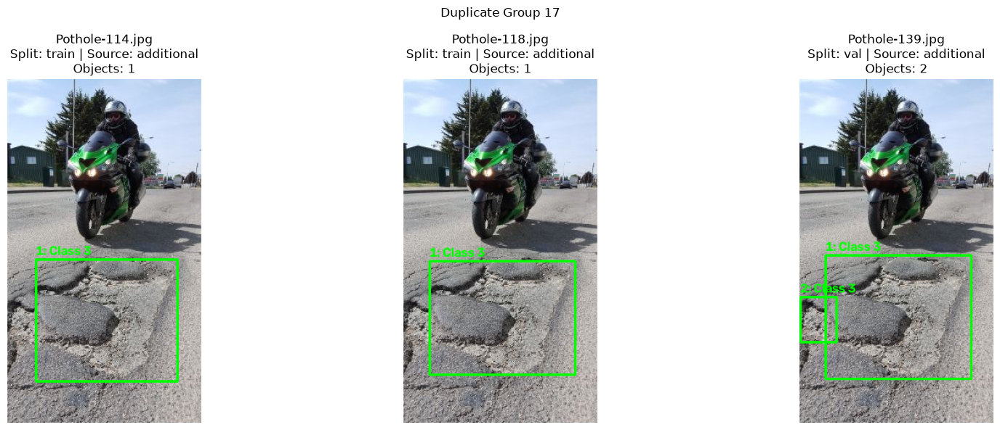

In [74]:
# Get the first 3 unresolved groups
next_groups = pending["group"].head(3).tolist()

for group_number in next_groups:
    inspect_duplicate_group(int(group_number))

In [75]:
import pandas as pd
from pathlib import Path

review_csv = Path.cwd() / "duplicate_review.csv"
decisions = pd.read_csv(review_csv)

selected = {
    12: "Pothole-219.jpg",
    14: "Pothole-228.jpg",
    17: "Pothole-114.jpg"
}

for group_number, filename in selected.items():

    row = decisions.loc[decisions["group"] == group_number]
    assert len(row) == 1

    choices = row.iloc[0]["choices"].split(" | ")

    matches = [
        int(choice.split(": ", 1)[0])
        for choice in choices
        if choice.split(": ", 1)[1].endswith("/" + filename)
    ]

    assert len(matches) == 1, f"Cannot uniquely find {filename}"

    decisions.loc[
        decisions["group"] == group_number,
        "keep_index"
    ] = matches[0]

    print(f"Group {group_number}: Keep {filename}")

decisions.to_csv(review_csv, index=False)

print("Decisions saved!")

Group 12: Keep Pothole-219.jpg
Group 14: Keep Pothole-228.jpg
Group 17: Keep Pothole-114.jpg
Decisions saved!


In [76]:
decisions = pd.read_csv(review_csv)

# Fill only unresolved groups
decisions["keep_index"] = decisions["keep_index"].fillna(0)

# Validate all selected indices
for row in decisions.itertuples():
    choices = row.choices.split(" | ")
    index = int(row.keep_index)

    assert row.keep_index == index
    assert 0 <= index < len(choices)

decisions.to_csv(review_csv, index=False)

print("Total groups:", len(decisions))
print("Completed:", decisions["keep_index"].notna().sum())
print("Remaining:", decisions["keep_index"].isna().sum())

Total groups: 37
Completed: 37
Remaining: 0


In [77]:
from pathlib import Path
import pandas as pd
import hashlib
from collections import Counter

project = Path.cwd()
datasets = project / "Datasets"

# Load all saved decisions
decisions = pd.read_csv(project / "duplicate_review.csv")

assert len(decisions) == len(duplicate_groups)
assert decisions["keep_index"].notna().all()

split_order = {"train": 0, "val": 1, "test": 2}

# Store images that should NOT be copied
remove_paths = set()

for group_number, group in enumerate(duplicate_groups, start=1):

    row = decisions.loc[
        decisions["group"] == group_number
    ].iloc[0]

    # Use the same ordering as duplicate_review.csv
    ordered = sorted(
        group,
        key=lambda item: (
            split_order[item[0]],
            str(item[1]).lower()
        )
    )

    choices = " | ".join(
        f"{i}: {split}/{image.name}"
        for i, (split, image) in enumerate(ordered)
    )

    # Ensure the CSV matches the current duplicate groups
    assert choices == row["choices"], (
        f"Group {group_number}: choices changed"
    )

    digest = hashlib.sha256(
        ordered[0][1].read_bytes()
    ).hexdigest()

    assert digest == row["image_hash"], (
        f"Group {group_number}: image hash changed"
    )

    keep_index = int(row["keep_index"])

    assert keep_index == row["keep_index"]
    assert 0 <= keep_index < len(ordered)

    # Remove every copy except the selected one
    for index, (split, image) in enumerate(ordered):
        if index != keep_index:
            remove_paths.add(image.resolve())


# Create new manifest without duplicate entries
deduplicated_manifest = [
    item for item in manifest
    if item[2].resolve() not in remove_paths
]

# Verify exactly one image remains in each group
for group in duplicate_groups:

    remaining = [
        image for split, image in group
        if image.resolve() not in remove_paths
    ]

    assert len(remaining) == 1

print("Original images:", len(manifest))
print("Duplicate images removed:", len(remove_paths))
print("Final images:", len(deduplicated_manifest))

print("\nFinal split counts:")
print(Counter(
    item[0] for item in deduplicated_manifest
))

Original images: 39091
Duplicate images removed: 51
Final images: 39040

Final split counts:
Counter({'train': 27336, 'test': 5855, 'val': 5849})


In [78]:
import shutil
from collections import Counter

final_dir = datasets / "RoadScan_Final"
building_dir = datasets / "RoadScan_Final_BUILDING"

# Never overwrite an existing dataset
assert not final_dir.exists(), "RoadScan_Final already exists"
assert not building_dir.exists(), "Incomplete build folder exists"

# Create output folders
for split in ["train", "val", "test"]:
    (building_dir / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (building_dir / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# Copy the deduplicated image-label pairs
for count, (split, source, image, label) in enumerate(
    deduplicated_manifest, start=1
):

    new_name = f"{source}_{image.stem}"

    image_dest = (
        building_dir / "images" / split /
        f"{new_name}{image.suffix.lower()}"
    )

    label_dest = (
        building_dir / "labels" / split /
        f"{new_name}.txt"
    )

    if image_dest.exists() or label_dest.exists():
        raise ValueError(f"Filename collision: {new_name}")

    shutil.copy2(image, image_dest)
    shutil.copy2(label, label_dest)

    if count % 5000 == 0:
        print(f"Copied {count} image-label pairs", flush=True)

# Create data.yaml
yaml_content = f"""path: "{final_dir.as_posix()}"

train: images/train
val: images/val
test: images/test

names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Pothole
  4: Water-Filled Pothole
"""

(building_dir / "data.yaml").write_text(
    yaml_content,
    encoding="utf-8"
)

# Mark the completed build as final
building_dir.rename(final_dir)

print("\nRoadScan_Final created successfully!")
print("Total images:", len(deduplicated_manifest))
print("Location:", final_dir)

Copied 5000 image-label pairs
Copied 10000 image-label pairs
Copied 15000 image-label pairs
Copied 20000 image-label pairs
Copied 25000 image-label pairs
Copied 30000 image-label pairs
Copied 35000 image-label pairs

RoadScan_Final created successfully!
Total images: 39040
Location: c:\Users\User\OneDrive\Desktop\RoadVision AI\Datasets\RoadScan_Final


In [79]:
from collections import Counter

final_counts = Counter()
class_counts = Counter()

for split in ["train", "val", "test"]:

    image_dir = final_dir / "images" / split
    label_dir = final_dir / "labels" / split

    image_names = {
        p.stem.lower()
        for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    }

    labels = list(label_dir.glob("*.txt"))

    label_names = {p.stem.lower() for p in labels}

    assert image_names == label_names, (
        f"Missing image-label matches in {split}"
    )

    final_counts[split] = len(image_names)

    for label in labels:
        for line in label.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])

                assert class_id in [0, 1, 2, 3, 4]

                class_counts[class_id] += 1

    print(f"{split.upper()}: {final_counts[split]} images")

print("\nTotal images:", sum(final_counts.values()))
print("Class distribution:", class_counts)

assert sum(final_counts.values()) == len(deduplicated_manifest)

print("\nFinal structural verification passed!")

TRAIN: 27336 images
VAL: 5849 images
TEST: 5855 images

Total images: 39040
Class distribution: Counter({0: 26013, 1: 11829, 2: 10616, 3: 7212, 4: 395})

Final structural verification passed!


In [80]:
from pathlib import Path
from collections import Counter

dataset = Path.cwd() / "Datasets" / "RoadScan_Final"

for split in ["train", "val", "test"]:
    counts = Counter()

    for file in (dataset / "labels" / split).glob("*.txt"):
        for line in file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[class_id] += 1

    print(f"\n{split.upper()}")
    for class_id in range(5):
        print(f"Class {class_id}: {counts[class_id]} objects")


TRAIN
Class 0: 18198 objects
Class 1: 8385 objects
Class 2: 7526 objects
Class 3: 5096 objects
Class 4: 265 objects

VAL
Class 0: 3890 objects
Class 1: 1769 objects
Class 2: 1553 objects
Class 3: 1066 objects
Class 4: 88 objects

TEST
Class 0: 3925 objects
Class 1: 1675 objects
Class 2: 1537 objects
Class 3: 1050 objects
Class 4: 42 objects
